# The Neural Network Zoo, Part 1: Classic and Alternative Architectures

> **Who is this for:** beginners and students who know what an MLP is and keep meeting names like "Hopfield network", "echo state network", "liquid neural network", "capsule network" or "hypernetwork" and want to know what each one actually does, whether anyone still uses it, and how it connects to today's models.
>
> **What you will learn:**
> - a **map of every major neural network family** and where each one is taught in this repo
> - for 16 "classic and alternative" networks: **how it works**, the **key maths** (in plain words and LaTeX), a **small runnable demo**, **where it is used today** and its **limits**
> - the perceptron and why XOR stopped it; RBF networks; extreme learning machines; self-organising maps
> - associative memory and energy: Hopfield networks (classic and modern), Boltzmann machines / RBMs / deep belief nets, energy-based models with Langevin sampling
> - time and the brain: echo state networks / reservoir computing, liquid time-constant networks and CfC, spiking neural networks with STDP and surrogate gradients
> - capsule networks, memory-augmented networks (memory networks, NTM, DNC), hypernetworks, mixture density networks, Bayesian neural networks, Siamese / triplet networks
>
> **Prerequisites:** [neural network fundamentals](01_neural_network_fundamentals.ipynb) and [neural networks from scratch in NumPy](18_neural_networks_from_scratch_numpy.ipynb). Helpful: [RNN / LSTM / GRU](04_rnn_lstm_gru.ipynb), [transformers](05_transformers_architecture.ipynb), [generative models](06_generative_models.ipynb).
>
> **Time needed:** about 3-4 hours to read and play (the notebook itself runs in about 1-2 minutes on a laptop CPU).
>
> **Runs on:** CPU, no API key, no internet. Uses numpy, scikit-learn, matplotlib and PyTorch (CPU). All data is generated in the notebook or comes with scikit-learn.

## Contents

0. Setup, and a map of all neural network families (and where each is taught)
1. The perceptron, its XOR failure, and the MLP / deep network
2. Radial basis function (RBF) networks
3. Extreme learning machines (ELM)
4. Self-organising maps (SOM, Kohonen maps)
5. Hopfield networks (classic and modern) and the link to attention
6. Boltzmann machines, restricted Boltzmann machines (RBM) and deep belief networks (DBN)
7. Energy-based models (EBM) and Langevin sampling
8. Echo state networks, reservoir computing and liquid state machines
9. Liquid time-constant (LTC) networks and closed-form continuous-time (CfC) networks
10. Spiking neural networks (SNN): LIF neurons, spike coding, STDP, surrogate gradients, neuromorphic chips
11. Capsule networks and dynamic routing
12. Memory-augmented networks: memory networks, neural Turing machines, differentiable neural computers
13. Hypernetworks
14. Mixture density networks (MDN)
15. Bayesian neural networks (BNN), MC dropout and deep ensembles
16. Siamese / triplet networks and deep metric learning, plus pointers to networks covered elsewhere
17. Summary table, interview questions, further reading

**How each section is built:** *What it is* -> *Simple analogy* -> *How it works (with the maths)* -> *Demo* -> *Used today?* -> *Limits*. The demos are deliberately tiny: they show the mechanism, not state-of-the-art results.

## 0. Setup and a map of the zoo

### 0.1 Setup

We fix the random seeds so you get the same numbers every time. `torch.set_num_threads(1)` makes our very small models faster (thread start-up costs more than it saves at this size).

In [1]:
import time, math, warnings
import numpy as np                                   # arrays and linear algebra
import matplotlib.pyplot as plt                      # plots
import torch                                         # PyTorch (CPU) for the demos that need gradients
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits             # 8x8 handwritten digits, ships with scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")                    # keep the output readable

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)                             # tiny models: one thread is faster
plt.rcParams["figure.dpi"] = 80                      # small figures
NB_START = time.time()                               # to report total run time at the end

digits = load_digits()                               # used by several sections
print("numpy", np.__version__, "| torch", torch.__version__)
print("digits:", digits.data.shape, "(1797 images of 8x8 pixels, values 0-16)")

numpy 2.5.4 | torch 2.15.0+cpu
digits: (1797, 64) (1797 images of 8x8 pixels, values 0-16)


### 0.2 A map of all neural network families

**What it is:** a "zoo" is just a catalogue. There are hundreds of named networks, but almost all of them are built from a small number of ideas: *how information flows* (forward only, in loops, through attention, over a graph), *what the network outputs* (a label, a number, a probability distribution, new data, its own weights), and *how it learns* (backprop, a local rule, least squares, sampling).

The famous picture-catalogue is the Asimov Institute's "Neural Network Zoo" (Fjodor van Veen, 2016). Here is a compact version, grouped by family.

```mermaid
flowchart TD
    NN["Neural networks"]
    NN --> FF["Feed-forward<br/>perceptron, MLP/DNN, RBF, ELM"]
    NN --> CONV["Convolutional<br/>CNN, ResNet, U-Net, TCN"]
    NN --> REC["Recurrent<br/>RNN, LSTM, GRU, ESN, LTC/CfC"]
    NN --> ATT["Attention<br/>Transformer, ViT"]
    NN --> GEN["Generative<br/>AE, VAE, GAN, diffusion, flows, EBM, RBM/DBN"]
    NN --> GRAPH["Graph<br/>GCN, GraphSAGE, GAT"]
    NN --> MEM["Memory-augmented<br/>memory networks, NTM, DNC"]
    NN --> PROB["Probabilistic<br/>BNN, MDN"]
    NN --> BIO["Biologically inspired<br/>SNN, Hopfield, SOM"]
    NN --> SCI["Scientific ML<br/>PINN, neural operators, neural ODE, KAN"]
    NN --> COND["Conditional computation<br/>mixture of experts, hypernetworks"]
    NN --> METRIC["Metric learning<br/>Siamese, triplet"]
```

| Family | Members | One-line idea | Where it is taught in this repo |
|---|---|---|---|
| Feed-forward | perceptron, MLP / DNN | layers of weighted sums + non-linearities, information flows one way | [01 fundamentals](01_neural_network_fundamentals.ipynb), [18 from scratch](18_neural_networks_from_scratch_numpy.ipynb), this notebook section 1 |
| Feed-forward | RBF network, extreme learning machine | fixed or random hidden layer, only the output layer is fitted | this notebook sections 2-3 |
| Convolutional | CNN, ResNet, U-Net, TCN | small filters slid over images / sequences; skip connections | [03 CNN](03_cnn.ipynb), [U-Net in segmentation](../06_Computer_Vision/04_image_segmentation.ipynb), [TCN in forecasting](../04_Forecasting/04_deep_learning_forecasting.ipynb) |
| Recurrent | RNN, LSTM, GRU | a hidden state carried through time | [04 RNN/LSTM/GRU](04_rnn_lstm_gru.ipynb), [19 sequence models hands-on](19_sequence_models_hands_on.ipynb) |
| Recurrent | echo state network, liquid state machine, LTC / CfC | fixed random reservoir, or neurons with input-dependent time constants | this notebook sections 8-9 |
| Attention | Transformer, Vision Transformer (ViT) | every token looks at every other token | [05 transformers](05_transformers_architecture.ipynb), [ViT](../06_Computer_Vision/05_vision_transformers.ipynb) |
| Generative | autoencoder, VAE, GAN, diffusion, normalizing flows | learn to produce new data | [06 generative models](06_generative_models.ipynb), [20 generative hands-on](20_generative_models_hands_on.ipynb) |
| Generative | energy-based models, Boltzmann machines, RBM, DBN | give low "energy" to likely data, sample by noisy descent | this notebook sections 6-7 |
| Graph | GNN (GCN, GraphSAGE, GAT) | message passing between connected nodes | [07 GNN](07_gnn.ipynb), [21 graph ML hands-on](21_graph_machine_learning_hands_on.ipynb) |
| Memory-augmented | memory networks, NTM, DNC | a network plus a readable / writable memory matrix | this notebook section 12; retrieval memory in [RAG fundamentals](../08_LLM/02_rag/01_rag_fundamentals.ipynb) |
| Probabilistic | Bayesian NN, mixture density network | output a distribution, not one number | this notebook sections 14-15; [probabilistic forecasting](../04_Forecasting/09_probabilistic_forecasting.ipynb) |
| Biologically inspired | spiking NN, Hopfield network, self-organising map | spikes, attractor memories, topographic maps | this notebook sections 4, 5, 10 |
| Scientific ML | PINN, neural operators, neural ODE, KAN | build physics or continuous time into the network | [10 neural ODE (and KAN)](10_neural_ode.ipynb); PINNs, neural operators and KAN in depth: [Part 2 of this zoo](24_neural_network_zoo_scientific_and_modern_architectures.ipynb) |
| Conditional computation | mixture of experts (MoE), hypernetworks | only some parameters are used, or one net makes another net's weights | MoE in [LLM architecture innovations](../08_LLM/14_llm_architecture_innovations.ipynb) and [Part 2 of this zoo](24_neural_network_zoo_scientific_and_modern_architectures.ipynb); hypernetworks in section 13 |
| Metric learning | Siamese, triplet networks | learn a distance: same things close, different things far | this notebook section 16; [self-supervised learning](09_self_supervised_learning.ipynb), [sentence embeddings](../07_NLP/09_sentence_embeddings_advanced.ipynb) |

Short mentions of several of these networks also appear in [uncommon ML models](../03_Machine_Learning/04_uncommon_models/01_uncommon_ml_models.ipynb).

**A useful way to read the zoo:** as of late 2026, most production systems use a handful of families (transformers, CNNs, MLPs, GNNs, diffusion models, gradient-boosted trees for tables). The networks in this notebook matter because (a) their ideas live on inside modern models (Hopfield -> attention, NTM -> retrieval and KV caches, hypernetworks -> adapter generators, EBMs -> diffusion), and (b) some of them are still the best tool in a niche (reservoir computing on tiny hardware, SNNs on neuromorphic chips, MDNs and BNNs when you need a distribution).

## 1. The perceptron, its XOR failure, and the MLP

**What it is:** the **perceptron** (Frank Rosenblatt, 1958) is a single artificial neuron: it multiplies each input by a weight, adds them up with a bias, and outputs 1 if the total is positive, otherwise 0. It was the first neural network that *learned* its weights from examples, and Rosenblatt built it in hardware (the Mark I Perceptron).

**Simple analogy:** a bouncer with a points system. Each feature of a guest adds or removes points; above the threshold you get in. Learning means adjusting the points after each wrong decision.

**How it works:**

$$\hat y = \text{step}(w \cdot x + b), \qquad \text{step}(z) = \begin{cases}1 & z \ge 0\\ 0 & z < 0\end{cases}$$

The **perceptron learning rule**: after each example, nudge the weights towards the right answer, and only when the answer was wrong:

$$w \leftarrow w + \eta\,(y - \hat y)\,x, \qquad b \leftarrow b + \eta\,(y - \hat y)$$

where $\eta$ (eta) is the **learning rate**, the size of each nudge. The **perceptron convergence theorem** says: if a straight line (a hyperplane in many dimensions) can separate the two classes, this rule finds one in a finite number of steps. If no such line exists, it never settles.

**A bit of history:** in 1969 Marvin Minsky and Seymour Papert's book *Perceptrons* showed that a single-layer perceptron cannot compute simple functions such as **XOR** (exclusive or: output 1 when exactly one input is 1), because XOR is not **linearly separable**. Interest and funding dropped (often called the first "AI winter" for neural nets). Multi-layer networks could solve XOR, but nobody had a good way to train them until **backpropagation** was popularised by Rumelhart, Hinton and Williams in 1986.

In [2]:
def step(z):
    return (z >= 0).astype(int)

def train_perceptron(X, y, epochs=20, lr=1.0):
    # Rosenblatt's rule: only change the weights when the prediction is wrong
    w, b = np.zeros(X.shape[1]), 0.0
    for epoch in range(epochs):
        mistakes = 0
        for xi, yi in zip(X, y):
            y_hat = step(xi @ w + b)
            if y_hat != yi:
                w += lr * (yi - y_hat) * xi
                b += lr * (yi - y_hat)
                mistakes += 1
        if mistakes == 0:          # a full pass with no mistakes: converged
            break
    return w, b, epoch + 1

X_bool = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
for name, y in {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}.items():
    y = np.array(y)
    w, b, ep = train_perceptron(X_bool, y)
    acc = (step(X_bool @ w + b) == y).mean()
    print(f"{name:3s}: weights={w}, bias={b:+.0f}, passes used={ep:2d}, accuracy={acc:.0%}")

AND: weights=[2. 1.], bias=-3, passes used= 6, accuracy=100%
OR : weights=[1. 1.], bias=-1, passes used= 4, accuracy=100%
XOR: weights=[-1.  0.], bias=+0, passes used=20, accuracy=50%


AND and OR converge in a few passes. XOR never does: the perceptron keeps cycling and can at best get 3 of the 4 points right, because no single straight line separates {(0,1),(1,0)} from {(0,0),(1,1)}.

**The fix: add a hidden layer.** A **multi-layer perceptron (MLP)** stacks layers: hidden units bend the space so that the classes become separable for the last layer. It needs a smooth activation (tanh, sigmoid, ReLU) instead of the step function, so that **backpropagation** (the chain rule applied layer by layer) can compute gradients. Below is a 2-4-1 MLP written in plain NumPy.

MLP outputs for (0,0),(0,1),(1,0),(1,1): [0.    0.999 0.999 0.001]
rounded: [0 1 1 0]  target: [0 1 1 0]


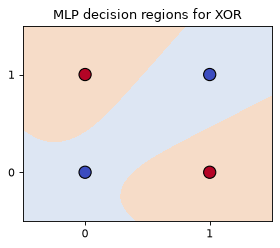

In [3]:
rng_xor = np.random.default_rng(1)
Xf = X_bool.astype(float)
yx = np.array([[0], [1], [1], [0]], float)
W1, b1 = rng_xor.normal(0, 1, (2, 4)), np.zeros(4)     # input -> 4 hidden units
W2, b2 = rng_xor.normal(0, 1, (4, 1)), np.zeros(1)     # hidden -> 1 output
sigmoid = lambda z: 1 / (1 + np.exp(-z))

for it in range(3000):
    h = np.tanh(Xf @ W1 + b1)              # forward pass: hidden layer
    p = sigmoid(h @ W2 + b2)               # output probability
    d_out = (p - yx) / len(Xf)             # gradient of cross-entropy w.r.t. the output logit
    dW2, db2 = h.T @ d_out, d_out.sum(0)
    d_h = (d_out @ W2.T) * (1 - h ** 2)    # chain rule through tanh
    dW1, db1 = Xf.T @ d_h, d_h.sum(0)
    for P, G in ((W1, dW1), (b1, db1), (W2, dW2), (b2, db2)):
        P -= 1.0 * G                       # gradient descent step (learning rate 1.0)

print("MLP outputs for (0,0),(0,1),(1,0),(1,1):", np.round(p.ravel(), 3))
print("rounded:", (p.ravel() > 0.5).astype(int), " target: [0 1 1 0]")

# picture: the perceptron can only draw a line, the MLP draws a curved region
g = np.linspace(-0.5, 1.5, 200)
GX, GY = np.meshgrid(g, g)
grid = np.c_[GX.ravel(), GY.ravel()]
Z = sigmoid(np.tanh(grid @ W1 + b1) @ W2 + b2).reshape(GX.shape)
plt.figure(figsize=(3.6, 3.2))
plt.contourf(GX, GY, Z, levels=[0, 0.5, 1], colors=["#dde6f3", "#f6dcc8"])
plt.scatter(Xf[:, 0], Xf[:, 1], c=yx.ravel(), cmap="coolwarm", s=120, edgecolor="k")
plt.title("MLP decision regions for XOR"); plt.xticks([0, 1]); plt.yticks([0, 1])
plt.tight_layout(); plt.show()

**Deep vs wide.** The **universal approximation theorem** (Cybenko 1989, Hornik 1991) says one hidden layer with *enough* units can approximate any continuous function on a bounded region. So why go deep (many layers, a **deep neural network, DNN**)?

| | Wide and shallow (1 big hidden layer) | Deep (many smaller layers) |
|---|---|---|
| What it can represent | anything, in theory | anything, in theory |
| Units needed for "composed" functions (parts of parts) | can grow exponentially | often far fewer: each layer reuses features of the layer below |
| Features | one level of features | a hierarchy (edges -> shapes -> objects) |
| Training difficulty | easy | needs good initialisation, normalisation, residual connections |
| Typical use today | small tabular problems, heads on top of other models | almost every modern model |

**Used today:** the single perceptron is used only for teaching (and as the neuron inside every network). MLPs are everywhere: the feed-forward block of every transformer is an MLP. **Limits:** a perceptron only draws straight lines; an MLP has no built-in knowledge of images, sequences or graphs, which is why CNNs, RNNs, transformers and GNNs exist. For the full treatment see [01 fundamentals](01_neural_network_fundamentals.ipynb) and [18 from scratch](18_neural_networks_from_scratch_numpy.ipynb).

## 2. Radial basis function (RBF) networks

**What it is:** an **RBF network** (Broomhead and Lowe, 1988) has one hidden layer of "bump" units. Each hidden unit has a **centre** $c_j$ and fires strongly when the input is close to its centre and weakly when far away. The output is a weighted sum of the bumps.

**Simple analogy:** a row of street lamps. Each lamp lights up the area around it; the brightness at any spot is the sum of nearby lamps, each turned up or down (the output weights) until the light pattern matches the shape you want.

**How it works:**

$$\phi_j(x) = \exp\!\left(-\frac{\lVert x - c_j\rVert^2}{2\sigma^2}\right), \qquad f(x) = \sum_{j=1}^{M} w_j\,\phi_j(x) + b$$

- $\phi_j$ is a **Gaussian** bump; $\sigma$ (sigma) sets its width.
- Training is usually done in two cheap stages: (1) pick the centres, e.g. with **k-means clustering**; (2) the output is *linear* in $w$, so solve for $w$ with **least squares** (one matrix equation, no gradient descent). We add a small **ridge** penalty $\lambda$ for stability:

$$w = (\Phi^\top \Phi + \lambda I)^{-1}\Phi^\top y$$

where $\Phi$ is the matrix of hidden activations (one row per example).

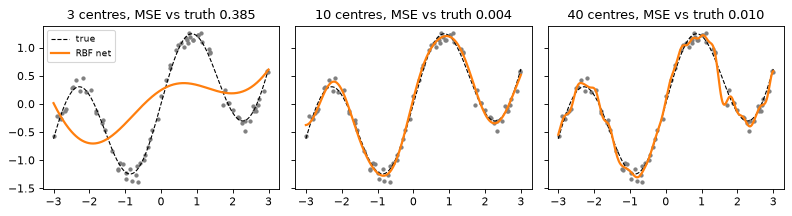

In [4]:
rng_rbf = np.random.default_rng(0)
true_f = lambda x: np.sin(2 * x) + 0.3 * x
x_tr = np.sort(rng_rbf.uniform(-3, 3, 80))
y_tr = true_f(x_tr) + rng_rbf.normal(0, 0.1, 80)        # noisy training points
x_grid = np.linspace(-3, 3, 300)

def rbf_features(x, centres, sigma):
    # one column per hidden unit: Gaussian bump around each centre
    return np.exp(-(x[:, None] - centres[None, :]) ** 2 / (2 * sigma ** 2))

def fit_rbf(x, y, n_centres, lam=1e-3):
    centres = np.sort(KMeans(n_centres, n_init=5, random_state=0).fit(x[:, None]).cluster_centers_.ravel())
    sigma = (x.max() - x.min()) / n_centres                # simple width rule: about the spacing
    Phi = np.c_[rbf_features(x, centres, sigma), np.ones(len(x))]   # + bias column
    w = np.linalg.solve(Phi.T @ Phi + lam * np.eye(Phi.shape[1]), Phi.T @ y)
    return centres, sigma, w

def predict_rbf(x, centres, sigma, w):
    return np.c_[rbf_features(x, centres, sigma), np.ones(len(x))] @ w

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, M in zip(axes, [3, 10, 40]):
    c, s, w = fit_rbf(x_tr, y_tr, M)
    pred = predict_rbf(x_grid, c, s, w)
    err = np.mean((pred - true_f(x_grid)) ** 2)
    ax.scatter(x_tr, y_tr, s=8, color="gray")
    ax.plot(x_grid, true_f(x_grid), "k--", lw=1, label="true")
    ax.plot(x_grid, pred, color="C1", lw=2, label="RBF net")
    ax.set_title(f"{M} centres, MSE vs truth {err:.3f}")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

Too few centres **underfit** (too smooth); a moderate number fits well; many narrow centres start to chase the noise (**overfit**), which the ridge penalty only partly controls.

**Used today:** the RBF idea is very much alive, but mostly *outside* the "network" name: the **RBF kernel** in support vector machines and Gaussian processes ([Gaussian processes notebook](../03_Machine_Learning/04_uncommon_models/02_industry_gaussian_process_process_optimization.ipynb)), **scattered-data interpolation** (e.g. `scipy.interpolate.RBFInterpolator` for terrain or sensor maps), mesh-free solvers for PDEs, and some control systems. RBF networks themselves are a fast, interpretable choice for low-dimensional regression.

**Limits:** the number of bumps needed to cover the input space grows exponentially with the number of input dimensions (**curse of dimensionality**), so RBF networks do not scale to images or text; results are sensitive to the width $\sigma$; and a Gaussian bump knows nothing about structure such as translation in images.

## 3. Extreme learning machines (ELM)

**What it is:** an **extreme learning machine** (Huang, Zhu and Siew, 2006) is an MLP with one hidden layer where the hidden weights are **random and never trained**. Only the output layer is learned, with a single least-squares solve. Very similar earlier ideas exist (random vector functional-link networks by Pao in 1994, Schmidt et al. 1992), and the name has been debated; the same principle appears as **random features** (Rahimi and Recht, 2007).

**Simple analogy:** instead of designing good questions to ask about each example, you ask 1,000 random questions and only learn how much to trust each answer.

**How it works:**

$$H = g(XW + b)\quad (W, b \text{ random, fixed}), \qquad \beta = (H^\top H + \lambda I)^{-1} H^\top Y, \qquad \hat Y = H\beta$$

- $g$ is a non-linearity (here tanh); $H$ holds the hidden activations; $\beta$ (beta) are the output weights.
- With enough random hidden units, the hidden layer is rich enough that a *linear* model on top works well. Training is one matrix solve, so it takes milliseconds.

In [5]:
Xd = digits.data / 16.0                                  # scale pixels to 0-1
Xtr_d, Xte_d, ytr_d, yte_d = train_test_split(Xd, digits.target, test_size=0.3, random_state=0, stratify=digits.target)
Ytr_onehot = np.eye(10)[ytr_d]                           # one-hot targets for least squares

def elm_fit_predict(n_hidden, lam=1e-1, seed=0):
    r = np.random.default_rng(seed)
    W = r.normal(0, 1 / np.sqrt(64), (64, n_hidden))     # random input weights (never trained)
    b = r.normal(0, 1, n_hidden)
    H = np.tanh(Xtr_d @ W + b)
    beta = np.linalg.solve(H.T @ H + lam * np.eye(n_hidden), H.T @ Ytr_onehot)   # the only "training"
    return (np.tanh(Xte_d @ W + b) @ beta).argmax(1)

for n_hidden in [50, 300, 1500]:
    t0 = time.time(); pred = elm_fit_predict(n_hidden)
    print(f"ELM, {n_hidden:5d} random hidden units: test accuracy {np.mean(pred == yte_d):.3f}  ({time.time() - t0:.3f}s)")

t0 = time.time()
lr_clf = LogisticRegression(max_iter=2000).fit(Xtr_d, ytr_d)
print(f"Logistic regression (baseline):       test accuracy {lr_clf.score(Xte_d, yte_d):.3f}  ({time.time() - t0:.3f}s)")

ELM,    50 random hidden units: test accuracy 0.935  (0.008s)
ELM,   300 random hidden units: test accuracy 0.991  (0.083s)


ELM,  1500 random hidden units: test accuracy 0.989  (1.180s)


Logistic regression (baseline):       test accuracy 0.970  (1.031s)


More random units help, up to a point, and training stays fast because there is no gradient descent.

**Used today:** ELMs are a niche method, mostly in research on fast training for embedded systems and some applied fields. The bigger legacy is the general idea "**random hidden features + trained linear readout**", which also powers random Fourier features for kernel methods and **reservoir computing** (section 8).

**Limits:** you usually need many more hidden units than a trained network; random features waste capacity; no hierarchy of learned features, so ELMs fall far behind CNNs and transformers on images, audio and text; performance depends on the random scale of $W$.

## 4. Self-organising maps (SOM, Kohonen maps)

**What it is:** a **self-organising map** (Teuvo Kohonen, 1982) is a grid of units (for example 20 x 20). Each unit holds a weight vector of the same size as the input. Training arranges the grid so that **nearby units represent similar inputs**. The result is a 2D "map" of high-dimensional data. It learns without labels (**unsupervised**) and without backpropagation.

**Simple analogy:** a crowd of people standing on a football pitch, each holding a paint colour. Every time a new colour is shown, the person with the closest colour steps forward, and they and their neighbours on the pitch mix a bit of the new colour into their own. After a while, similar colours stand next to each other.

**How it works (one training step):**

1. Pick an input $x$.
2. Find the **best matching unit (BMU)**: $c = \arg\min_j \lVert x - w_j \rVert$.
3. Pull the BMU *and its grid neighbours* towards $x$:

$$w_j \leftarrow w_j + \eta(t)\, h_{cj}(t)\,(x - w_j), \qquad h_{cj}(t) = \exp\!\left(-\frac{d_{\text{grid}}(c, j)^2}{2\sigma(t)^2}\right)$$

$d_{\text{grid}}$ is the distance *on the grid* (not in input space). The learning rate $\eta(t)$ and neighbourhood radius $\sigma(t)$ shrink over time: first the map organises globally, then it fine-tunes locally.

**Demo:** map random RGB colours (3 numbers each) onto a 20 x 20 grid.

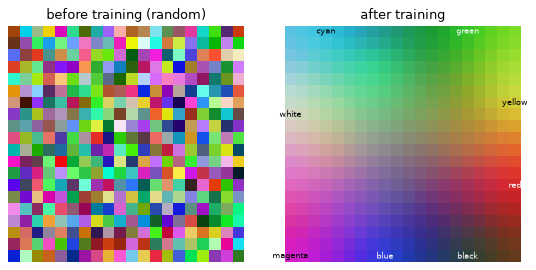

average distance from a new colour to its best unit (quantisation error): 0.126


In [6]:
rng_som = np.random.default_rng(0)
GRID = 20
W_som = rng_som.random((GRID, GRID, 3))              # each unit holds an RGB colour (random start)
W_start = W_som.copy()
gy, gx = np.mgrid[0:GRID, 0:GRID]                     # grid coordinates of every unit
train_colours = rng_som.random((3000, 3))

n_steps, sigma0, lr0 = 3000, GRID / 2, 0.5
for t, x in enumerate(train_colours):
    frac = t / n_steps
    sigma = sigma0 * (0.5 / sigma0) ** frac           # neighbourhood shrinks from 10 to 0.5 units
    lr = lr0 * (0.01 / lr0) ** frac                   # learning rate shrinks from 0.5 to 0.01
    dist = ((W_som - x) ** 2).sum(-1)                 # distance from x to every unit's colour
    by, bx = np.unravel_index(dist.argmin(), dist.shape)          # best matching unit
    h = np.exp(-((gy - by) ** 2 + (gx - bx) ** 2) / (2 * sigma ** 2))   # neighbourhood on the grid
    W_som += lr * h[..., None] * (x - W_som)

named = {"red": [1, 0, 0], "green": [0, 1, 0], "blue": [0, 0, 1], "yellow": [1, 1, 0],
         "cyan": [0, 1, 1], "magenta": [1, 0, 1], "white": [1, 1, 1], "black": [0, 0, 0]}
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
axes[0].imshow(W_start); axes[0].set_title("before training (random)")
axes[1].imshow(W_som); axes[1].set_title("after training")
for name, col in named.items():
    d = ((W_som - np.array(col)) ** 2).sum(-1)
    yy, xx = np.unravel_index(d.argmin(), d.shape)
    axes[1].text(xx, yy, name, fontsize=7, ha="center", va="center",
                 color="white" if sum(col) < 1.5 else "black")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

qe = np.mean([np.sqrt(((W_som - x) ** 2).sum(-1).min()) for x in rng_som.random((500, 3))])
print(f"average distance from a new colour to its best unit (quantisation error): {qe:.3f}")

The random noise turns into smooth regions where similar colours are neighbours: the map has **preserved topology** (closeness in input space becomes closeness on the grid).

**Used today:** SOMs are still used for **exploratory visualisation and clustering** in fields such as geoscience, process monitoring, customer segmentation and some anomaly detection (a new point far from every unit is suspicious). Libraries such as MiniSom make them easy to try.

**Limits:** there is no single loss function that training minimises, so it is hard to judge quality; you must choose grid size and decay schedules by hand; for pure visualisation, t-SNE and UMAP usually give clearer pictures; for clustering, k-means or Gaussian mixtures are simpler.

## 5. Hopfield networks (classic and modern) and the link to attention

**What it is:** a **Hopfield network** (John Hopfield, 1982) is a network of binary neurons (+1 or -1) that are all connected to each other with symmetric weights. It works as an **associative memory** (also called content-addressable memory): you store a few patterns, then give it a *noisy or partial* pattern, and it "falls" back to the closest stored one. John Hopfield shared the 2024 Nobel Prize in Physics with Geoffrey Hinton for this line of work (energy-based networks).

**Simple analogy:** a landscape of valleys. Each stored memory is the bottom of a valley. Drop a ball (a noisy pattern) anywhere on a slope and it rolls down into the nearest valley (the clean memory).

**How it works:**

- **Storage (Hebbian learning, "neurons that fire together wire together"):** for $P$ patterns $\xi^\mu \in \{-1,+1\}^N$,
$$W = \frac{1}{N}\sum_{\mu=1}^{P} \xi^\mu (\xi^\mu)^\top, \qquad W_{ii} = 0$$
- **Recall:** update neurons one at a time: $s_i \leftarrow \text{sign}\big(\sum_j W_{ij} s_j\big)$.
- **Energy:** $E(s) = -\tfrac12\, s^\top W s$. Each one-at-a-time update can only keep $E$ the same or lower it, so the network always settles in a **local minimum** (a valley). Stored patterns are (ideally) those minima.
- **Capacity:** with random patterns, recall works only while $P \lesssim 0.14\,N$ (Amit, Gutfreund and Sompolinsky, 1985). Above that, memories interfere and **spurious states** (mixtures of memories) take over.

memory 0: energy per sweep [-15.  -50.6 -50.6 -50.6 -50.6] -> overlap with original +1.00
memory 1: energy per sweep [-11.5 -50.2 -50.2 -50.2 -50.2] -> overlap with original +1.00
memory 2: energy per sweep [-11.3 -49.1 -49.1 -49.1 -49.1] -> overlap with original +1.00


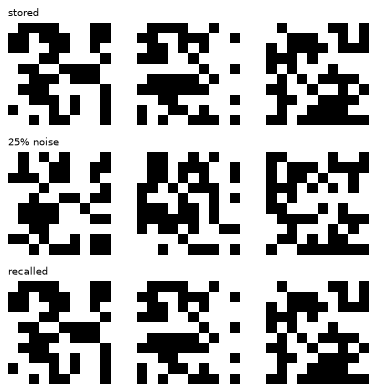

In [7]:
rng_h = np.random.default_rng(3)
N_H, P_H = 100, 3                                         # 100 neurons shown as 10x10 images, 3 memories
patterns = rng_h.choice([-1, 1], size=(P_H, N_H))
W_hop = patterns.T @ patterns / N_H                       # Hebbian storage
np.fill_diagonal(W_hop, 0)

def energy(s):
    return -0.5 * s @ W_hop @ s

def recall(s, sweeps=4):
    s = s.copy(); E = [energy(s)]
    for _ in range(sweeps):
        for i in rng_h.permutation(N_H):                  # asynchronous: one neuron at a time
            s[i] = 1 if W_hop[i] @ s >= 0 else -1
        E.append(energy(s))
    return s, E

fig, axes = plt.subplots(3, P_H, figsize=(5, 5))
for k in range(P_H):
    noisy = patterns[k].copy()
    flip = rng_h.choice(N_H, 25, replace=False)          # corrupt 25% of the pixels
    noisy[flip] *= -1
    rec, E = recall(noisy)
    overlap = rec @ patterns[k] / N_H                     # 1.0 means perfect recall
    print(f"memory {k}: energy per sweep {np.round(E, 1)} -> overlap with original {overlap:+.2f}")
    for row, img, title in zip(range(3), [patterns[k], noisy, rec], ["stored", "25% noise", "recalled"]):
        axes[row, k].imshow(img.reshape(10, 10), cmap="gray"); axes[row, k].axis("off")
        if k == 0: axes[row, k].set_title(title, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

The energy goes down with each sweep and the network recovers the stored pattern. Now the **capacity** limit: store more and more random patterns in $N = 200$ neurons, start from each stored pattern, let the network run, and measure how much of the pattern survives.

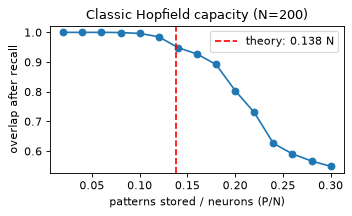

In [8]:
def capacity_curve(N=200, alphas=np.linspace(0.02, 0.30, 15), trials=4, seed=0):
    r = np.random.default_rng(seed); out = []
    for a in alphas:
        P = max(1, int(round(a * N))); ov = []
        for _ in range(trials):
            pats = r.choice([-1, 1], size=(P, N))
            W = pats.T @ pats / N; np.fill_diagonal(W, 0)
            S = pats.copy()
            for _ in range(10):                            # synchronous updates (fast, vectorised)
                S = np.where(S @ W >= 0, 1, -1)
            ov.append(np.mean(np.sum(S * pats, 1) / N))    # average overlap with the stored patterns
        out.append(np.mean(ov))
    return alphas, np.array(out)

alphas, overlaps = capacity_curve()
plt.figure(figsize=(4.5, 2.8))
plt.plot(alphas, overlaps, "o-")
plt.axvline(0.138, color="red", ls="--", label="theory: 0.138 N")
plt.xlabel("patterns stored / neurons (P/N)"); plt.ylabel("overlap after recall")
plt.title("Classic Hopfield capacity (N=200)"); plt.legend(); plt.tight_layout(); plt.show()

Recall is almost perfect for small loads and degrades around $P/N \approx 0.14$ (with only 200 neurons the drop is smoothed out; it becomes sharper for large $N$). That is a tiny capacity: 14 memories for 100 neurons.

**Modern Hopfield networks.** Krotov and Hopfield (2016, "dense associative memory") and Ramsauer et al. (2020, "Hopfield Networks is All You Need") changed the energy to use an exponential (log-sum-exp) instead of a quadratic. With continuous states and stored patterns as the rows of a matrix $X$, the update becomes

$$\xi^{\text{new}} = X^\top \operatorname{softmax}\!\big(\beta\, X \xi\big)$$

Read it as: compare the query $\xi$ with every stored pattern (dot products), turn the scores into weights with a softmax, and return the weighted average of the stored patterns. This is **exactly the attention formula** $\operatorname{softmax}(q K^\top) V$ with the stored patterns acting as both keys $K$ and values $V$, and $\beta$ playing the role of $1/\sqrt{d}$. The capacity becomes **exponential** in $N$, and retrieval usually takes one step.

In [9]:
P_big = 40                                           # 40 memories in 100 neurons: far above 0.14 N = 14
mem = rng_h.choice([-1, 1], size=(P_big, N_H)).astype(float)
target = mem[0].copy(); query = target.copy()
query[rng_h.choice(N_H, 20, replace=False)] *= -1        # 20% noise

# classic Hopfield with the same 40 memories
W_big = mem.T @ mem / N_H; np.fill_diagonal(W_big, 0)
s = query.copy()
for _ in range(5):
    for i in rng_h.permutation(N_H):
        s[i] = 1 if W_big[i] @ s >= 0 else -1
print(f"classic Hopfield, 40 memories: overlap with the right memory = {s @ target / N_H:+.2f}")

# modern Hopfield: one softmax-attention step over the stored patterns
beta = 0.5
weights = np.exp(beta * (mem @ query - (mem @ query).max())); weights /= weights.sum()   # softmax
xi_new = mem.T @ weights
print(f"modern Hopfield (one attention step): overlap = {np.sign(xi_new) @ target / N_H:+.2f}")
print(f"attention weight on the right memory: {weights[0]:.3f} (next largest {np.sort(weights)[-2]:.3g})")

classic Hopfield, 40 memories: overlap with the right memory = +0.46
modern Hopfield (one attention step): overlap = +1.00
attention weight on the right memory: 1.000 (next largest 1.13e-07)


**Used today:** classic Hopfield networks are mostly a teaching and theory tool (they also inspired optimisation methods and analogue hardware). **Modern Hopfield layers** appear in research libraries (for example the `hopfield-layers` package for PyTorch), in immune-repertoire classification, and in the interpretation of transformers and memory. Their main legacy is conceptual: *attention can be viewed as one step of associative memory retrieval.*

**Limits:** the classic model has low capacity and spurious memories, needs symmetric weights, and works with binary patterns; modern versions are essentially attention, so in practice you simply use attention.

## 6. Boltzmann machines, restricted Boltzmann machines (RBM) and deep belief networks (DBN)

**What it is:** a **Boltzmann machine** (Hinton and Sejnowski, 1985) is a Hopfield-like network with *random* (stochastic) binary neurons and some **hidden units**. Instead of falling into one valley, it samples states with probability that depends on their energy, so it learns a **probability distribution** over data. A **restricted Boltzmann machine (RBM)** removes connections inside each layer: visible units only connect to hidden units. That restriction makes it practical to train.

**Simple analogy:** the hidden units are a committee of "feature detectors". Looking at an image (visible units), each detector votes on whether its feature is present. Looking at the votes, the network can redraw the image. Training makes redrawn images look like real ones.

**How it works:**

- **Energy** of a visible vector $v$ and hidden vector $h$ (all 0/1): $E(v,h) = -a^\top v - b^\top h - v^\top W h$, and $p(v,h) = e^{-E(v,h)}/Z$, where $Z$ (the **partition function**) sums $e^{-E}$ over all possible states and is impossible to compute exactly for real sizes.
- Because there are no within-layer connections, each layer is easy to sample given the other:
$$p(h_j = 1 \mid v) = \sigma\big(b_j + v^\top W_{:,j}\big), \qquad p(v_i = 1 \mid h) = \sigma\big(a_i + W_{i,:}\, h\big)$$
- **Contrastive divergence (CD-1)** (Hinton, 2002): the exact gradient needs samples from the model, which are expensive. CD-1 replaces them with a one-step reconstruction:
$$\Delta W = \eta\left(\langle v\,h^\top\rangle_{\text{data}} - \langle v\,h^\top\rangle_{\text{reconstruction}}\right)$$
In words: strengthen the connections seen in real data, weaken those seen in the model's own reconstructions.

**Demo:** train an RBM with CD-1 on binarised 8 x 8 digits, then fill in images whose bottom half is missing.

In [10]:
Xb = (digits.data > 7).astype(float)                     # binary 8x8 images (pixel on / off)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, digits.target, test_size=0.3, random_state=0, stratify=digits.target)
rng_r = np.random.default_rng(0)
n_v, n_h = 64, 64
W_r = rng_r.normal(0, 0.01, (n_v, n_h))
p_on = Xb_tr.mean(0).clip(0.01, 0.99)
a_r = np.log(p_on / (1 - p_on))                         # visible biases start at the pixel log-odds
b_r = np.zeros(n_h)

def h_given_v(v): p = sigmoid(v @ W_r + b_r);   return p, (rng_r.random(p.shape) < p).astype(float)
def v_given_h(h): p = sigmoid(h @ W_r.T + a_r); return p, (rng_r.random(p.shape) < p).astype(float)

lr_r, batch = 0.05, 32
for epoch in range(30):
    errs = []
    order = rng_r.permutation(len(Xb_tr))                 # shuffle each epoch
    for i in range(0, len(Xb_tr), batch):
        v0 = Xb_tr[order[i:i + batch]]
        ph0, h0 = h_given_v(v0)                         # positive phase: data
        pv1, _ = v_given_h(h0)                          # one Gibbs step: reconstruction
        ph1, _ = h_given_v(pv1)                         # negative phase
        W_r += lr_r * (v0.T @ ph0 - pv1.T @ ph1) / len(v0)
        a_r += lr_r * (v0 - pv1).mean(0)
        b_r += lr_r * (ph0 - ph1).mean(0)
        errs.append(np.mean((v0 - pv1) ** 2))
    if epoch % 10 == 9:
        print(f"epoch {epoch + 1:2d}: reconstruction error {np.mean(errs):.4f}")

epoch 10: reconstruction error 0.1037


epoch 20: reconstruction error 0.0794


epoch 30: reconstruction error 0.0669


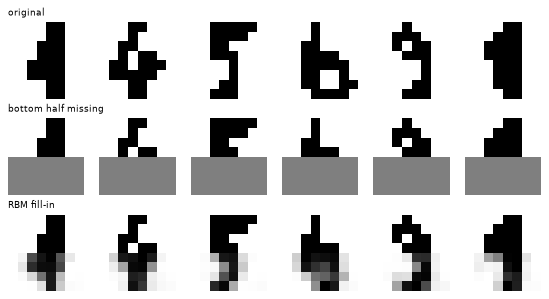

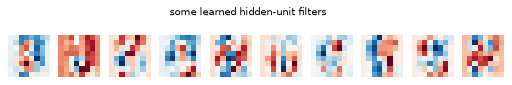

logistic regression on binary pixels: 0.930 | on 64 RBM features: 0.907


In [11]:
# 1) fill in missing bottom halves of test images by Gibbs sampling with the top half clamped
test_imgs = Xb_te[:6].copy()
v = test_imgs.copy(); v[:, 32:] = rng_r.random((6, 32)) < 0.5     # bottom half replaced by noise
for _ in range(50):
    _, h = h_given_v(v)
    pv, _ = v_given_h(h)
    v[:, 32:] = pv[:, 32:]                                         # only update the missing half
filled = v

# 2) learned features: each hidden unit's weights shown as an 8x8 image
fig, axes = plt.subplots(3, 6, figsize=(7, 3.8))
for k in range(6):
    corrupted = test_imgs[k].copy(); corrupted[32:] = 0.5
    for row, img in enumerate([test_imgs[k], corrupted, filled[k]]):
        axes[row, k].imshow(img.reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); axes[row, k].axis("off")
axes[0, 0].set_title("original", fontsize=8, loc="left")
axes[1, 0].set_title("bottom half missing", fontsize=8, loc="left")
axes[2, 0].set_title("RBM fill-in", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 10, figsize=(8, 1.1))
for k, ax in enumerate(axes):
    ax.imshow(W_r[:, k].reshape(8, 8), cmap="RdBu"); ax.axis("off")
plt.suptitle("some learned hidden-unit filters", fontsize=9, y=1.05); plt.show()

# 3) RBM hidden units as features for a classifier (how RBMs were used in the 2000s)
feat_tr, feat_te = sigmoid(Xb_tr @ W_r + b_r), sigmoid(Xb_te @ W_r + b_r)
acc_raw = LogisticRegression(max_iter=2000).fit(Xb_tr, yb_tr).score(Xb_te, yb_te)
acc_rbm = LogisticRegression(max_iter=2000).fit(feat_tr, yb_tr).score(feat_te, yb_te)
print(f"logistic regression on binary pixels: {acc_raw:.3f} | on 64 RBM features: {acc_rbm:.3f}")

The RBM fills in blurry but plausible strokes (we show pixel probabilities, so uncertain pixels are grey) because it has learned which pixels tend to be on together. Its 64 hidden features do not beat raw pixels for this small, easy classification task; in the 2000s the gains came from stacking several RBMs and fine-tuning (next paragraph). scikit-learn ships a ready-made version as `sklearn.neural_network.BernoulliRBM`.

**Deep belief networks (history).** Hinton, Osindero and Teh (2006) showed that you can **stack RBMs**: train one RBM on the pixels, then a second RBM on the first one's hidden activations, and so on (**greedy layer-wise pretraining**), and finally fine-tune the whole stack with backpropagation. This **deep belief network (DBN)** was one of the results that restarted interest in deep learning, because it made networks with many layers trainable at the time. Within a few years, ReLU activations, better weight initialisation, dropout, GPUs and large labelled datasets made plain backprop work without pretraining, and DBNs faded.

**Used today:** mostly historical in mainstream ML. RBMs survive in a few niches: **neural quantum states** in physics (Carleo and Troyer, 2017, used an RBM to represent quantum wave functions), some collaborative-filtering work (RBMs were part of strong Netflix Prize entries, Salakhutdinov, Mnih and Hinton 2007), and teaching energy-based learning.

**Limits:** the partition function $Z$ is intractable, so likelihoods are hard to measure; CD gives biased gradients; sampling can mix slowly between modes; binary units suit only some data; modern generative models (VAEs, diffusion, autoregressive transformers) are easier to train and scale.

## 7. Energy-based models (EBM) and Langevin sampling

**What it is:** an **energy-based model** is the general idea behind Hopfield networks and RBMs: a network $E_\theta(x)$ outputs one number, the **energy**, for any input $x$. Low energy means "likely / compatible", high energy means "unlikely". Probabilities follow the **Boltzmann distribution**

$$p_\theta(x) = \frac{e^{-E_\theta(x)}}{Z_\theta}, \qquad Z_\theta = \int e^{-E_\theta(x)}\,dx$$

Yann LeCun and colleagues popularised this general view ("A Tutorial on Energy-Based Learning", 2006). The energy can be any neural network, which makes EBMs very flexible.

**Simple analogy:** a hilly landscape over the space of all possible inputs. Training digs valleys where real data lives and raises hills everywhere else. Sampling means letting a ball roll downhill while it is being shaken.

**How it works:**

- **Training (contrastive idea):** the gradient of the log-likelihood has two parts:
$$\nabla_\theta \log p_\theta(x) = -\nabla_\theta E_\theta(x_{\text{data}}) + \mathbb{E}_{x' \sim p_\theta}\big[\nabla_\theta E_\theta(x')\big]$$
In words: **push the energy down on real data, push it up on samples the model currently generates** ("negative samples"). A simple loss that does this is $\mathcal{L} = E_\theta(x_{\text{data}}) - E_\theta(x_{\text{neg}})$ plus a small penalty on the energy size for stability (Du and Mordatch, 2019).
- **Sampling (Langevin dynamics):** start from noise and follow the downhill direction plus a little noise:
$$x_{k+1} = x_k - \frac{\epsilon}{2}\nabla_x E_\theta(x_k) + \sqrt{\epsilon}\; z_k, \qquad z_k \sim \mathcal N(0, I)$$
With small steps and many iterations, $x$ becomes a sample from $p_\theta$. The quantity $-\nabla_x E$ is called the **score**; learning the score directly is what **score-based diffusion models** do.

First, Langevin sampling on a *known* energy (a double well) to see that it really produces samples from $e^{-E}$:

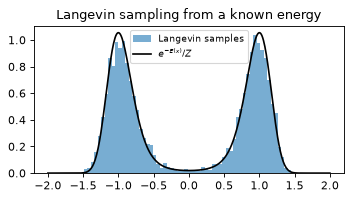

In [12]:
E_dw = lambda x: 4 * (x ** 2 - 1) ** 2             # double-well energy: valleys at x = -1 and x = +1
grad_dw = lambda x: 16 * x * (x ** 2 - 1)
rng_l = np.random.default_rng(0)
x = rng_l.uniform(-2, 2, 5000)                      # 5000 particles starting anywhere
eps = 0.01
for _ in range(500):
    x = x - 0.5 * eps * grad_dw(x) + np.sqrt(eps) * rng_l.standard_normal(x.shape)

xs = np.linspace(-2, 2, 400); dens = np.exp(-E_dw(xs)); dens /= dens.sum() * (xs[1] - xs[0])   # normalise so it integrates to 1
plt.figure(figsize=(4.5, 2.6))
plt.hist(x, bins=60, density=True, alpha=0.6, label="Langevin samples")
plt.plot(xs, dens, "k", label=r"$e^{-E(x)}/Z$")
plt.title("Langevin sampling from a known energy"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

Now we **learn** an energy network for 2D data (six blobs on a ring) with the contrastive loss. Negative samples come from short Langevin chains that start from a **replay buffer** of earlier samples (persistent chains), which is a standard trick to make short chains good enough.

In [13]:
torch.manual_seed(0); rng_e = np.random.default_rng(0)
K_RING = 6
ring = np.c_[2 * np.cos(np.arange(K_RING) * 2 * np.pi / K_RING), 2 * np.sin(np.arange(K_RING) * 2 * np.pi / K_RING)]
def sample_ring(n):
    return torch.tensor(ring[rng_e.integers(K_RING, size=n)] + 0.15 * rng_e.standard_normal((n, 2)), dtype=torch.float32)

energy_net = nn.Sequential(nn.Linear(2, 64), nn.SiLU(), nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 1))
opt_e = torch.optim.Adam(energy_net.parameters(), lr=1e-3)

def langevin(x, steps, eps):
    x = x.clone().requires_grad_(True)
    for _ in range(steps):
        g, = torch.autograd.grad(energy_net(x).sum(), x)          # gradient of the energy w.r.t. the input
        x = (x - 0.5 * eps * g + math.sqrt(eps) * torch.randn_like(x)).detach().requires_grad_(True)
    return x.detach()

buffer = torch.rand(2000, 2) * 6 - 3                               # replay buffer of negative samples
t0 = time.time()
for it in range(1200):
    x_data = sample_ring(128)
    idx = torch.randint(0, len(buffer), (128,))
    x0 = buffer[idx]
    fresh = torch.rand(128) < 0.05                                 # 5% restart from pure noise
    x0[fresh] = torch.rand(int(fresh.sum()), 2) * 6 - 3
    x_neg = langevin(x0, steps=15, eps=0.02)
    buffer[idx] = x_neg
    e_pos, e_neg = energy_net(x_data), energy_net(x_neg)
    loss = e_pos.mean() - e_neg.mean() + 0.1 * (e_pos ** 2 + e_neg ** 2).mean()   # contrastive + regulariser
    opt_e.zero_grad(); loss.backward(); opt_e.step()
    if it % 400 == 0:
        print(f"iter {it:4d}: mean energy data {e_pos.mean().item():+.2f} | negatives {e_neg.mean().item():+.2f}")
print(f"training time {time.time() - t0:.1f}s")

iter    0: mean energy data +0.03 | negatives -0.01


iter  400: mean energy data -0.29 | negatives +0.17


iter  800: mean energy data -0.20 | negatives +0.14


training time 14.8s


fraction of fresh Langevin samples within 0.5 of a true blob centre: 0.85


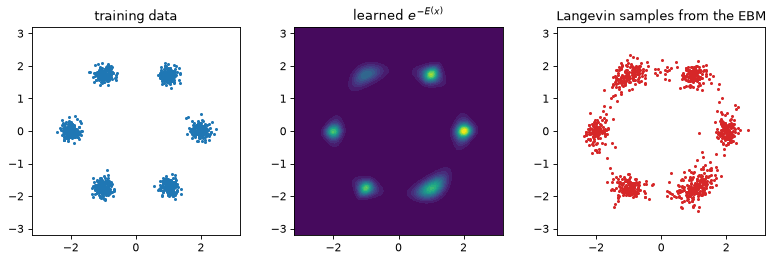

In [14]:
samples = langevin(torch.rand(1000, 2) * 6 - 3, steps=300, eps=0.01).numpy()   # fresh chains from noise
d_near = np.min(np.linalg.norm(samples[:, None] - ring[None], axis=2), axis=1)
print(f"fraction of fresh Langevin samples within 0.5 of a true blob centre: {np.mean(d_near < 0.5):.2f}")

g = np.linspace(-3.2, 3.2, 120); GX, GY = np.meshgrid(g, g)
with torch.no_grad():
    En = energy_net(torch.tensor(np.c_[GX.ravel(), GY.ravel()], dtype=torch.float32)).numpy().reshape(GX.shape)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].scatter(*sample_ring(1000).numpy().T, s=3); axes[0].set_title("training data")
axes[1].contourf(GX, GY, np.exp(-(En - En.min())), levels=20, cmap="viridis"); axes[1].set_title(r"learned $e^{-E(x)}$")
axes[2].scatter(*samples.T, s=3, color="C3"); axes[2].set_title("Langevin samples from the EBM")
for ax in axes: ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

The network has dug six valleys where the data lives, and noisy gradient descent on the learned energy produces new points in those valleys.

**Used today:** "pure" EBMs are mostly research, but the energy view is everywhere: **score-based diffusion models** learn $-\nabla_x E$ at many noise levels ([generative models](06_generative_models.ipynb)); the **energy score** $-\log\sum_k e^{f_k(x)}$ of a classifier is a popular out-of-distribution detector (Liu et al., 2020); EBMs can be **composed** by adding energies (concept A AND concept B); and LeCun's joint-embedding predictive architectures (JEPA) are described as energy-based. Contrastive learning losses (section 16) are also energy-style objectives.

**Limits:** sampling is slow (hundreds of gradient steps per sample); training can be unstable (energies blow up or collapse) and needs tricks such as replay buffers and regularisers; the likelihood cannot be computed exactly because of $Z$; diffusion models usually give better samples with more stable training.

## 8. Echo state networks, reservoir computing and liquid state machines

**What it is:** an **echo state network (ESN)** (Herbert Jaeger, 2001) is a recurrent network whose big recurrent part, the **reservoir**, is random and **never trained**. Only a linear **readout** from the reservoir state to the output is trained, with least squares. This family of methods is called **reservoir computing**. A **liquid state machine (LSM)** (Wolfgang Maass, Natschlager and Markram, 2002) is the same idea with a reservoir of *spiking* neurons.

**Simple analogy:** throw stones into a pond. The ripples (reservoir state) are a rich, fading echo of every stone thrown recently. You do not control the water; you only learn how to read the ripples to say what was thrown and what comes next. (The "liquid" in liquid state machine refers to exactly this picture.)

**How it works:**

$$x(t+1) = (1-a)\,x(t) + a\,\tanh\!\big(W_{\text{in}}\,[1; u(t)] + W\,x(t)\big), \qquad y(t) = W_{\text{out}}\,[1; u(t); x(t)]$$

- $u(t)$ is the input, $x(t)$ the reservoir state (hundreds of units), $a$ the **leak rate** (how fast the state changes).
- $W_{\text{in}}$ and $W$ are random. $W$ is rescaled so that its **spectral radius** $\rho$ (its largest absolute eigenvalue) is around 1. Roughly: $\rho < 1$ means echoes fade (the **echo state property**: the state depends on the recent input, not on the starting state); too small and memory is short, too large and the reservoir becomes chaotic.
- Training: collect the states, then **ridge regression**: $W_{\text{out}} = Y X^\top (X X^\top + \lambda I)^{-1}$. No backpropagation through time.

**Demo:** predict the **Mackey-Glass** series, a classic chaotic time series from a delay differential equation $\dot x(t) = \frac{0.2\,x(t-\tau)}{1 + x(t-\tau)^{10}} - 0.1\,x(t)$ with $\tau = 17$. We train one-step-ahead prediction, then let the ESN **run freely**, feeding back its own predictions for 500 steps.

ESN (400 units, rho=1.25), trained in 2.20s
  free-running error (NRMSE) over the first 100 steps: 0.007
  free-running error (NRMSE) over the first 300 steps: 0.016
  free-running error (NRMSE) over the first 500 steps: 0.061


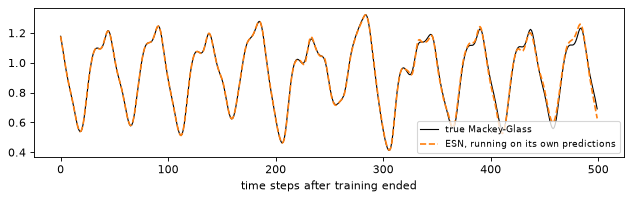

In [15]:
def mackey_glass(n, tau=17, dt=0.1, sub=10):
    # Euler integration of the delay equation, then keep every 10th point (time step 1)
    hist = int(round(tau / dt)); total = (n + 200) * sub
    x = np.full(total + hist, 1.2)
    for t in range(hist, total + hist - 1):
        xd = x[t - hist]
        x[t + 1] = x[t] + dt * (0.2 * xd / (1 + xd ** 10) - 0.1 * x[t])
    return x[hist::sub][200:200 + n]                    # drop the start-up transient

mg = mackey_glass(3000)
INIT, TRAIN, TEST = 100, 2000, 500

def run_esn(rho, N=400, leak=0.3, reg=1e-8, seed=42):
    r = np.random.default_rng(seed)
    W_in = (r.random((N, 2)) - 0.5) * 1.0
    W = r.random((N, N)) - 0.5
    W *= rho / np.max(np.abs(np.linalg.eigvals(W)))     # set the spectral radius
    X = np.zeros((N + 2, TRAIN - INIT)); x = np.zeros(N)
    for t in range(TRAIN):                              # drive the reservoir with the true series
        x = (1 - leak) * x + leak * np.tanh(W_in @ np.r_[1, mg[t]] + W @ x)
        if t >= INIT: X[:, t - INIT] = np.r_[1, mg[t], x]
    Y = mg[INIT + 1:TRAIN + 1]                          # target: the next value
    W_out = np.linalg.solve(X @ X.T + reg * np.eye(N + 2), X @ Y)   # ridge regression readout
    u, pred = mg[TRAIN], np.zeros(TEST)
    for t in range(TEST):                               # free run: feed predictions back in
        x = (1 - leak) * x + leak * np.tanh(W_in @ np.r_[1, u] + W @ x)
        u = W_out @ np.r_[1, u, x]; pred[t] = u
    return pred

truth = mg[TRAIN + 1:TRAIN + 1 + TEST]
nrmse = lambda p, h: np.sqrt(np.mean((p[:h] - truth[:h]) ** 2)) / np.std(truth)
t0 = time.time(); pred = run_esn(rho=1.25)
print(f"ESN (400 units, rho=1.25), trained in {time.time() - t0:.2f}s")
for h in [100, 300, 500]:
    print(f"  free-running error (NRMSE) over the first {h} steps: {nrmse(pred, h):.3f}")

plt.figure(figsize=(8, 2.6))
plt.plot(np.arange(TEST), truth, "k", lw=1, label="true Mackey-Glass")
plt.plot(np.arange(TEST), pred, "C1--", lw=1.5, label="ESN, running on its own predictions")
plt.xlabel("time steps after training ended"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**NRMSE** (normalised root mean squared error) divides the error by the standard deviation of the signal, so 0 is perfect and 1 is as bad as predicting the mean. The ESN tracks a *chaotic* signal for hundreds of steps with a readout fitted in well under a second. Now, how much does the spectral radius matter?

In [16]:
for rho in [0.3, 0.8, 1.25, 1.6]:
    print(f"spectral radius {rho:4.2f}: free-run NRMSE over 300 steps = {nrmse(run_esn(rho), 300):.3f}")

spectral radius 0.30: free-run NRMSE over 300 steps = 0.325


spectral radius 0.80: free-run NRMSE over 300 steps = 0.130


spectral radius 1.25: free-run NRMSE over 300 steps = 0.016


spectral radius 1.60: free-run NRMSE over 300 steps = 0.334


The spectral radius changes the result a lot: it sets how long the reservoir remembers and how rich its dynamics are. This sensitivity to a few hyperparameters (spectral radius, leak rate, input scaling, regularisation) is typical of reservoir computing. (A value above 1 can still work because the tanh and the input keep the driven reservoir stable.)

**Used today:** reservoir computing is an active niche: forecasting chaotic or nonlinear systems, signal equalisation, and especially **physical reservoir computing**, where the "reservoir" is a physical system (photonic circuits, spintronic devices, memristors, even a bucket of water) and only a cheap linear readout is trained. It suits very small edge devices that cannot run backprop. Recent variants include "next-generation reservoir computing" (Gauthier et al., 2021).

**Limits:** memory is limited by reservoir size; a random reservoir wastes capacity compared to a trained RNN; hyperparameters need tuning; on large datasets, trained LSTMs, temporal CNNs and transformers ([04](04_rnn_lstm_gru.ipynb), [19](19_sequence_models_hands_on.ipynb)) usually win. LSMs add the extra cost of simulating spiking neurons (section 10).

## 9. Liquid time-constant (LTC) networks and closed-form continuous-time (CfC) networks

**What it is:** **liquid time-constant networks** (Hasani, Lechner, Amini, Rus and Grosu, AAAI 2021) are recurrent networks whose neurons are small **ordinary differential equations (ODEs)**: equations that say how fast each neuron's state changes. The special feature is that each neuron's **time constant** (how quickly it reacts and forgets) is not fixed: it changes with the input. The networks are often marketed as "liquid neural networks". **CfC** (closed-form continuous-time networks, Hasani et al., *Nature Machine Intelligence* 2022) replaces the ODE solver with an approximate closed-form formula so they run much faster.

**Simple analogy:** a car's suspension that becomes stiffer or softer depending on the road. On a smooth road it reacts slowly; when it hits a bump (a strong input) it reacts fast.

**How it works:**

- An ordinary leaky neuron: $\dfrac{dx}{dt} = -\dfrac{x}{\tau} + f(x, I)$ with a fixed time constant $\tau$ (tau).
- An **LTC neuron**:
$$\frac{dx}{dt} = -\Big[\frac{1}{\tau} + f(x, I;\theta)\Big]\,x + f(x, I;\theta)\,A$$
where $f$ is a small neural network (with positive output, e.g. a sigmoid) of the state $x$ and input $I$, and $A$ is a learned bias vector. The **effective time constant** is
$$\tau_{\text{sys}} = \frac{1}{1/\tau + f(x, I)} = \frac{\tau}{1 + \tau f(x, I)},$$
so a stronger drive $f$ makes the neuron respond faster. The state also stays bounded (between 0 and $A$ when starting there), which makes LTCs stable.
- The paper integrates the ODE with a **fused semi-implicit Euler step**: $x_{t+\Delta t} = \dfrac{x_t + \Delta t\, f\, A}{1 + \Delta t\,(1/\tau + f)}$.
- **CfC** approximates the solution directly as a time-dependent gate between two learned targets:
$$x(t) = \sigma\big(-f(x, I)\,t\big)\odot g(x, I) + \big[1 - \sigma\big(-f(x, I)\,t\big)\big]\odot h(x, I)$$
where $f, g, h$ are small network heads and $t$ is the elapsed time. Because $t$ appears explicitly, both models handle **irregularly sampled time series** naturally.

LTC and CfC are close relatives of **neural ODEs**, covered in [10 neural ODE](10_neural_ode.ipynb).

**Demo 1:** one LTC neuron, step input of different strengths. Watch the response speed change.

input strength 0.5: drive f = 0.27, effective time constant = 0.79 (fixed tau = 1.0)
input strength 1.5: drive f = 0.73, effective time constant = 0.58 (fixed tau = 1.0)
input strength 4.0: drive f = 1.00, effective time constant = 0.50 (fixed tau = 1.0)


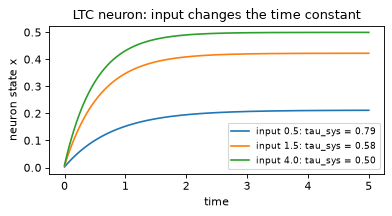

In [17]:
tau, A_ltc = 1.0, 1.0
f_drive = lambda I: sigmoid(2.0 * I - 2.0)              # the neuron's small "network": positive drive
ts = np.linspace(0, 5, 500); dt = ts[1] - ts[0]
plt.figure(figsize=(5, 2.8))
for I in [0.5, 1.5, 4.0]:
    x, xs_ = 0.0, []
    for _ in ts:
        f = f_drive(I)
        x = (x + dt * f * A_ltc) / (1 + dt * (1 / tau + f))   # fused semi-implicit Euler step
        xs_.append(x)
    tau_sys = 1 / (1 / tau + f_drive(I))
    plt.plot(ts, xs_, label=f"input {I}: tau_sys = {tau_sys:.2f}")
    print(f"input strength {I}: drive f = {f_drive(I):.2f}, effective time constant = {tau_sys:.2f} (fixed tau = {tau})")
plt.xlabel("time"); plt.ylabel("neuron state x"); plt.title("LTC neuron: input changes the time constant")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**Demo 2:** train an LTC cell, a CfC cell and a standard GRU (as a baseline, see [04](04_rnn_lstm_gru.ipynb)) on an **irregularly sampled** task: damped oscillations measured at random time gaps. At each step the model sees the current value and the time gap $\Delta t$ to the next measurement and must predict the next value. All three have 16 hidden units.

In [18]:
rng_t = np.random.default_rng(0)
def make_irregular(n, L=40):
    dts = rng_t.uniform(0.05, 0.5, (n, L)); t = np.cumsum(dts, 1)          # random time gaps
    freq, ph, damp = rng_t.uniform(0.8, 2.0, (n, 1)), rng_t.uniform(0, 2 * np.pi, (n, 1)), rng_t.uniform(0, 0.15, (n, 1))
    s = np.exp(-damp * t) * np.sin(freq * t + ph)
    inp = np.stack([s[:, :-1], dts[:, 1:]], -1)                              # (value now, gap to next)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return to_t(inp), to_t(s[:, 1:]), to_t(dts[:, 1:])
Xs_tr, Ys_tr, Ds_tr = make_irregular(512); Xs_te, Ys_te, Ds_te = make_irregular(256)

class LTCCell(nn.Module):
    def __init__(self, n_in, n_hid, unfolds=3):
        super().__init__()
        self.inp, self.rec = nn.Linear(n_in, n_hid), nn.Linear(n_hid, n_hid, bias=False)
        self.log_tau = nn.Parameter(torch.zeros(n_hid)); self.A = nn.Parameter(torch.randn(n_hid) * 0.5)
        self.unfolds = unfolds
    def forward(self, u, x, dt):
        d = dt[:, None] / self.unfolds
        for _ in range(self.unfolds):                          # a few small ODE steps per input
            f = torch.sigmoid(self.inp(u) + self.rec(x))      # positive, input- and state-dependent drive
            x = (x + d * f * self.A) / (1 + d * (1 / self.log_tau.exp() + f))
        return x

class CfCCell(nn.Module):
    def __init__(self, n_in, n_hid, n_backbone=16):
        super().__init__()
        self.backbone = nn.Linear(n_in + n_hid, n_backbone)
        self.f, self.g, self.h = (nn.Linear(n_backbone, n_hid) for _ in range(3))
    def forward(self, u, x, dt):
        z = torch.tanh(self.backbone(torch.cat([u, x], -1)))
        gate = torch.sigmoid(-self.f(z) * dt[:, None])        # time-dependent gate (closed form, no solver)
        return gate * torch.tanh(self.g(z)) + (1 - gate) * torch.tanh(self.h(z))

class GRUCellWrap(nn.Module):
    def __init__(self, n_in, n_hid): super().__init__(); self.cell = nn.GRUCell(n_in, n_hid)
    def forward(self, u, x, dt): return self.cell(u, x)       # ignores dt except through the input

class SeqModel(nn.Module):
    def __init__(self, cell, n_hid): super().__init__(); self.cell, self.n_hid, self.out = cell, n_hid, nn.Linear(n_hid, 1)
    def forward(self, X, D):
        x, ys = torch.zeros(X.shape[0], self.n_hid), []
        for k in range(X.shape[1]):
            x = self.cell(X[:, k], x, D[:, k]); ys.append(self.out(x))
        return torch.cat(ys, -1)

H_SEQ = 16
for name, make_cell in [("LTC", lambda: LTCCell(2, H_SEQ)), ("CfC", lambda: CfCCell(2, H_SEQ)), ("GRU", lambda: GRUCellWrap(2, H_SEQ))]:
    torch.manual_seed(0); t0 = time.time()
    model = SeqModel(make_cell(), H_SEQ); opt = torch.optim.Adam(model.parameters(), lr=1e-2)
    for epoch in range(40):
        perm = torch.randperm(len(Xs_tr))
        for b in range(0, len(Xs_tr), 128):
            i = perm[b:b + 128]
            loss = F.mse_loss(model(Xs_tr[i], Ds_tr[i])[:, 5:], Ys_tr[i][:, 5:])   # skip 5 warm-up steps
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        test_mse = F.mse_loss(model(Xs_te, Ds_te)[:, 5:], Ys_te[:, 5:]).item()
    n_par = sum(p.numel() for p in model.parameters())
    print(f"{name}: {n_par:5d} parameters, test MSE {test_mse:.4f}, train time {time.time() - t0:.1f}s")
print(f"(for scale: predicting the average every time would give MSE {Ys_te[:, 5:].var().item():.3f})")

LTC:   353 parameters, test MSE 0.0365, train time 11.8s


CfC:  1137 parameters, test MSE 0.0025, train time 4.0s


GRU:   977 parameters, test MSE 0.0039, train time 3.0s
(for scale: predicting the average every time would give MSE 0.230)


All three errors are far below the "always predict the average" baseline, so all three learned the dynamics. In this short run the CfC and the GRU are more accurate than the LTC, which has about a third of their parameters and trains more slowly because it runs a small ODE solver inside every step; CfC removes the solver. Rankings on a toy like this change with seeds and tuning, so do not read it as a benchmark.

**Used today:** LTC/CfC models have been demonstrated in robot and drone control, autonomous-driving lane keeping with very small **neural circuit policies** (Lechner et al., *Nature Machine Intelligence* 2020, with 19 control neurons), and time-series tasks with irregular sampling. A company (Liquid AI) was spun out of this research; its later "liquid foundation models" are a broader family of efficient architectures, not simply large LTC networks. Open-source implementations exist (the `ncps` package for PyTorch and Keras).

**Limits:** the ODE versions are slow to train; on standard large benchmarks, transformers and modern state-space models are the usual choice; claimed advantages (robustness, interpretability with few neurons) are mostly shown on small control tasks; the community and tooling are small compared to mainstream architectures.

## 10. Spiking neural networks (SNN)

**What it is:** in a **spiking neural network**, neurons communicate with short all-or-nothing events (**spikes**) at specific moments in time, like real neurons, instead of sending a real number every step. Information is in *when* and *how often* neurons spike. SNNs are called the "third generation" of neural networks (Maass, 1997). Their appeal is **energy efficiency** on special **neuromorphic** hardware: when nothing spikes, almost nothing is computed.

**Simple analogy:** a bucket with a small hole, being filled by a tap. Water (input current) raises the level (membrane voltage); the hole slowly leaks it away. When the water reaches the rim, the bucket tips over (a spike) and starts empty again.

**How it works: the leaky integrate-and-fire (LIF) neuron**

$$\tau_m \frac{dV}{dt} = -(V - V_{\text{rest}}) + R\,I(t), \qquad \text{if } V \ge V_{\text{th}}:\ \text{emit a spike and reset } V \leftarrow V_{\text{reset}}$$

- $V$ is the **membrane potential**, $\tau_m$ the membrane time constant (the leak), $I(t)$ the input current, $R$ the resistance, $V_{\text{th}}$ the firing threshold.
- In discrete time this becomes $V_{t+1} = \beta V_t + I_t$ with $\beta = e^{-\Delta t/\tau_m}$, which is how most SNN libraries implement it.

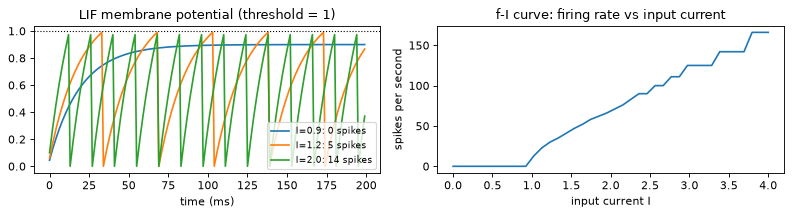

In [19]:
def simulate_lif(I, T=200, dt=1.0, tau_m=20.0, v_rest=0.0, v_th=1.0, v_reset=0.0, R=1.0):
    v, vs, spikes = v_rest, [], []
    for t in range(T):
        v += dt / tau_m * (-(v - v_rest) + R * I)      # leaky integration (Euler step)
        if v >= v_th:                                   # threshold crossed: spike and reset
            spikes.append(t); v = v_reset
        vs.append(v)
    return np.array(vs), spikes

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
for I in [0.9, 1.2, 2.0]:
    vs, sp = simulate_lif(I)
    axes[0].plot(vs, label=f"I={I}: {len(sp)} spikes")
axes[0].axhline(1.0, color="k", ls=":", lw=1); axes[0].set_title("LIF membrane potential (threshold = 1)")
axes[0].set_xlabel("time (ms)"); axes[0].legend(fontsize=8)
currents = np.linspace(0, 4, 40)
rates = [len(simulate_lif(I, T=1000)[1]) for I in currents]      # spikes per second (T = 1000 ms)
axes[1].plot(currents, rates); axes[1].set_title("f-I curve: firing rate vs input current")
axes[1].set_xlabel("input current I"); axes[1].set_ylabel("spikes per second")
plt.tight_layout(); plt.show()

Below the threshold current ($I = 0.9$) the neuron never fires: the leak wins. Above it, the firing rate grows with the input: the **f-I curve** (frequency vs current) is the spiking version of an activation function.

**Spike coding: how numbers become spikes.**

| Code | Idea | Pros | Cons |
|---|---|---|---|
| **Rate coding** | a bigger value means more spikes per second (often random **Poisson** spikes) | robust, simple, easy to train | needs many time steps, so many spikes (energy) |
| **Temporal / latency coding** | a bigger value means an *earlier* first spike | very few spikes, fast | sensitive to timing noise |
| Others | phase coding, population coding, burst coding | richer | more complex |

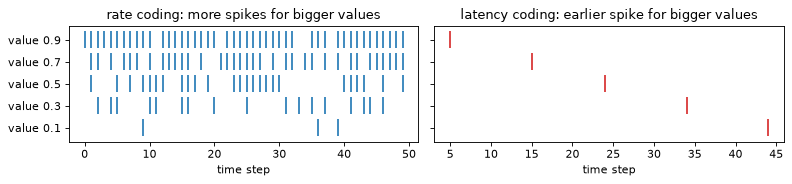

In [20]:
rng_s = np.random.default_rng(1)
intensities = [0.1, 0.3, 0.5, 0.7, 0.9]
T_code = 50                                             # 50 time steps
fig, axes = plt.subplots(1, 2, figsize=(10, 2.4), sharey=True)
for k, p in enumerate(intensities):
    rate_spikes = np.where(rng_s.random(T_code) < p)[0]                 # Poisson-like rate code
    axes[0].vlines(rate_spikes, k - 0.4, k + 0.4)
    latency = int(round((1 - p) * (T_code - 1)))                       # one spike: brighter = earlier
    axes[1].vlines([latency], k - 0.4, k + 0.4, color="C3")
axes[0].set_title("rate coding: more spikes for bigger values"); axes[1].set_title("latency coding: earlier spike for bigger values")
axes[0].set_yticks(range(5)); axes[0].set_yticklabels([f"value {p}" for p in intensities])
for ax in axes: ax.set_xlabel("time step")
plt.tight_layout(); plt.show()

**Learning rule 1: STDP (spike-timing-dependent plasticity).** A local, biologically observed rule (Bi and Poo, 1998; Song, Miller and Abbott, 2000): if an input spike arrives *just before* the neuron fires, it probably helped cause the spike, so the connection gets stronger; if it arrives *just after*, it gets weaker. With $\Delta t = t_{\text{post}} - t_{\text{pre}}$:

$$\Delta w = \begin{cases} A_+\, e^{-\Delta t/\tau_+} & \Delta t > 0 \ \ \text{(pre before post: strengthen)}\\ -A_-\, e^{\Delta t/\tau_-} & \Delta t < 0 \ \ \text{(post before pre: weaken)}\end{cases}$$

No gradients, no labels: each synapse only needs the timing of its own two neurons. In code we keep a decaying **trace** of recent spikes for each side, which gives the same result efficiently.

**Demo:** one LIF neuron with 50 inputs. Inputs 0-9 tend to fire *together* (a hidden pattern); inputs 10-49 fire randomly at a similar rate. Will STDP discover the correlated group?

output neuron fired at 9.1 Hz
mean weight, correlated inputs 0-9: 1.00 | random inputs 10-49: 0.46


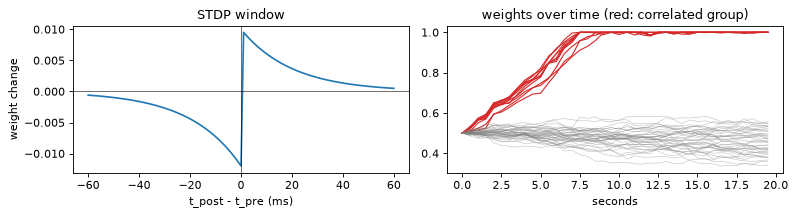

In [21]:
A_plus, A_minus, tau_stdp = 0.01, 0.012, 20.0
dts_ = np.arange(-60, 61)
window = np.where(dts_ > 0, A_plus * np.exp(-dts_ / tau_stdp), -A_minus * np.exp(dts_ / tau_stdp))

rng_p = np.random.default_rng(0)
n_in, n_corr, rate = 50, 10, 10 / 1000          # 10 Hz inputs, 1 ms steps
w = np.full(n_in, 0.5)
w_hist, v, pre_trace, post_trace, n_post = [], 0.0, np.zeros(n_in), 0.0, 0
for t in range(20000):                          # 20 seconds of simulated time
    shared_event = rng_p.random() < rate
    pre = rng_p.random(n_in) < rate                                         # background inputs
    pre[:n_corr] = (shared_event & (rng_p.random(n_corr) < 0.8)) | (rng_p.random(n_corr) < rate * 0.2)
    pre_trace *= np.exp(-1 / tau_stdp); post_trace *= np.exp(-1 / tau_stdp)
    pre_trace[pre] += 1
    v += -v / 20.0 + 0.12 * (w @ pre)                                       # LIF neuron, tau_m = 20 ms
    w[pre] -= A_minus * post_trace                                          # pre after post: weaken
    if v >= 1.0:
        v = 0.0; n_post += 1; post_trace += 1
        w += A_plus * pre_trace                                             # pre before post: strengthen
    np.clip(w, 0, 1, out=w)
    if t % 500 == 0: w_hist.append(w.copy())

w_hist = np.array(w_hist)
print(f"output neuron fired at {n_post / 20:.1f} Hz")
print(f"mean weight, correlated inputs 0-9: {w[:n_corr].mean():.2f} | random inputs 10-49: {w[n_corr:].mean():.2f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
axes[0].plot(dts_, window); axes[0].axhline(0, color="k", lw=0.5); axes[0].axvline(0, color="k", lw=0.5)
axes[0].set_title("STDP window"); axes[0].set_xlabel("t_post - t_pre (ms)"); axes[0].set_ylabel("weight change")
axes[1].plot(np.arange(len(w_hist)) * 0.5, w_hist[:, :n_corr], color="C3", lw=1)
axes[1].plot(np.arange(len(w_hist)) * 0.5, w_hist[:, n_corr:], color="gray", lw=0.5, alpha=0.5)
axes[1].set_title("weights over time (red: correlated group)"); axes[1].set_xlabel("seconds")
plt.tight_layout(); plt.show()

STDP strengthens exactly the inputs that fire together, because they are the ones that reliably arrive just before the output spikes. That is unsupervised pattern detection with a purely local rule.

**Learning rule 2: surrogate gradients.** To train SNNs with backprop like normal networks, we hit a wall: the spike function is a step $S = \Theta(V - V_{\text{th}})$, whose derivative is zero everywhere except at the threshold (where it is infinite). **Surrogate gradient** training (Neftci, Mostafa and Zenke, 2019) keeps the real step in the forward pass but uses a smooth stand-in derivative in the backward pass, for example the "fast sigmoid":

$$\frac{\partial S}{\partial V} \approx \frac{1}{\big(1 + k\,\lvert V - V_{\text{th}}\rvert\big)^2}$$

Then the network is unrolled over time and trained with backpropagation through time, just like an RNN. **Demo:** a 64-128-10 SNN on the digits, with rate-coded (Poisson) input spikes over 15 time steps.

In [22]:
class SpikeFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, v):                     # forward: the real, non-differentiable step
        ctx.save_for_backward(v)
        return (v > 0).float()
    @staticmethod
    def backward(ctx, grad_out):             # backward: smooth surrogate derivative (fast sigmoid)
        v, = ctx.saved_tensors
        return grad_out / (1 + 10 * v.abs()) ** 2
spike_fn = SpikeFn.apply

class TinySNN(nn.Module):
    def __init__(self, T=15, beta=0.9):
        super().__init__(); self.fc1, self.fc2, self.T, self.beta = nn.Linear(64, 128), nn.Linear(128, 10), T, beta
    def forward(self, x):
        v1, v2 = torch.zeros(x.shape[0], 128), torch.zeros(x.shape[0], 10)
        out, n_spikes = 0, 0
        for t in range(self.T):
            inp = (torch.rand_like(x) < x).float()          # rate coding: pixel brightness = spike probability
            v1 = self.beta * v1 + self.fc1(inp)              # leaky integration
            s1 = spike_fn(v1 - 1.0)                          # spike if above threshold 1
            v1 = v1 - s1                                     # soft reset after a spike
            v2 = self.beta * v2 + self.fc2(s1)               # output neurons just integrate (no spikes)
            out, n_spikes = out + v2, n_spikes + s1.sum()
        return out / self.T, n_spikes / (x.shape[0] * self.T * 128)

Xt_tr, Xt_te = torch.tensor(Xtr_d, dtype=torch.float32), torch.tensor(Xte_d, dtype=torch.float32)
yt_tr, yt_te = torch.tensor(ytr_d), torch.tensor(yte_d)
torch.manual_seed(0); snn = TinySNN(); opt_s = torch.optim.Adam(snn.parameters(), lr=2e-3); t0 = time.time()
for epoch in range(10):
    perm = torch.randperm(len(Xt_tr))
    for b in range(0, len(Xt_tr), 64):
        i = perm[b:b + 64]
        loss = F.cross_entropy(snn(Xt_tr[i])[0], yt_tr[i])
        opt_s.zero_grad(); loss.backward(); opt_s.step()
with torch.no_grad():
    logits, spike_rate = snn(Xt_te)
print(f"SNN test accuracy {(logits.argmax(1) == yt_te).float().mean():.3f} after {time.time() - t0:.1f}s; "
      f"hidden neurons spiked on {spike_rate:.0%} of time steps")

SNN test accuracy 0.963 after 1.4s; hidden neurons spiked on 32% of time steps


A spiking network trained with surrogate gradients reaches accuracy close to an ordinary MLP on this small task. On neuromorphic hardware, energy is spent roughly per spike, so the **spike rate** printed above is the number engineers try to push down.

**Neuromorphic hardware (brief, as of late 2026):** Intel **Loihi** and **Loihi 2** research chips (and the large Hala Point system built from Loihi 2 chips), IBM **TrueNorth** (2014) and its successor research chip NorthPole (which is not spiking but brain-inspired), the University of Manchester's **SpiNNaker** systems, and commercial edge chips such as BrainChip **Akida**. They are usually paired with **event cameras** (sensors that output a spike-like event only when a pixel changes). Software: snnTorch, Norse, SpikingJelly, Intel Lava.

**Used today:** research, computational neuroscience, and low-power edge sensing (keyword spotting, gesture recognition, event-camera vision, some robotics). **Limits:** training is harder and slower than for normal networks (many time steps, surrogate gradients); accuracy usually trails standard networks on large tasks; the energy advantage only appears on neuromorphic hardware, which is not widely available; on GPUs an SNN is typically *slower* than an equivalent ANN.

## 11. Capsule networks and dynamic routing

**What it is:** a **capsule network** (Sabour, Frosst and Hinton, 2017, "Dynamic Routing Between Capsules") replaces single neurons with **capsules**: small groups of neurons whose output is a **vector**. The vector's **length** is the probability that some entity (an eye, a nose, a face) is present; its **direction** encodes the entity's **pose** (position, rotation, size). Higher-level capsules are activated when lower-level capsules **agree** about the pose of the whole.

**Simple analogy:** a face detector that does not just check "there is an eye, a nose and a mouth somewhere" (which a scrambled face also passes) but asks each part: "if you are part of a face, where do you think the face is?" Only when the parts *agree* on the same face position is the face capsule switched on.

**How it works:**

1. Each lower capsule $i$ (output $u_i$) makes a **prediction** for each higher capsule $j$ with a learned matrix: $\hat u_{j|i} = W_{ij}\, u_i$.
2. **Routing by agreement** (repeated for a few iterations), starting with logits $b_{ij} = 0$:
$$c_{ij} = \operatorname{softmax}_j(b_{ij}), \qquad s_j = \sum_i c_{ij}\, \hat u_{j|i}, \qquad v_j = \operatorname{squash}(s_j), \qquad b_{ij} \leftarrow b_{ij} + \hat u_{j|i}\cdot v_j$$
The coupling coefficients $c_{ij}$ say how much part $i$ sends to whole $j$; they grow when a part's prediction agrees (large dot product) with the consensus $v_j$.
3. The **squash** non-linearity keeps the direction but maps the length into $[0, 1)$:
$$\operatorname{squash}(s) = \frac{\lVert s\rVert^2}{1 + \lVert s\rVert^2}\,\frac{s}{\lVert s\rVert}$$

**Demo:** 8 lower capsules (parts) and 2 higher capsules ("face" and "house"). We set up the predictions so that parts 0-3 agree on one face pose, while parts 4-7 make random predictions and nobody agrees on a house.

In [23]:
def squash(s, axis=-1, eps=1e-9):
    n2 = (s ** 2).sum(axis, keepdims=True)
    return n2 / (1 + n2) * s / np.sqrt(n2 + eps)

rng_c = np.random.default_rng(1)
n_lower, n_upper, dim = 8, 2, 4
face_pose = np.array([1.0, 0.5, -0.5, 0.8])
u_hat = rng_c.normal(0, 0.3, (n_lower, n_upper, dim))         # predictions u_hat[i, j] = W_ij u_i
u_hat[:4, 0] = face_pose + rng_c.normal(0, 0.05, (4, dim))     # parts 0-3 agree on the face pose

b = np.zeros((n_lower, n_upper))                               # routing logits
for it in range(3):
    c = np.exp(b) / np.exp(b).sum(1, keepdims=True)            # softmax over higher capsules
    s = (c[..., None] * u_hat).sum(0)                          # weighted sum of predictions
    v = squash(s)                                              # higher capsule outputs
    b = b + (u_hat * v[None]).sum(-1)                          # agreement = dot product
    print(f"iteration {it + 1}: length(face) = {np.linalg.norm(v[0]):.2f}, length(house) = {np.linalg.norm(v[1]):.2f}")

print("\ncoupling coefficients c_ij (rows: parts 0-7, columns: face, house):")
print(np.round(c, 2))

iteration 1: length(face) = 0.89, length(house) = 0.20
iteration 2: length(face) = 0.95, length(house) = 0.17
iteration 3: length(face) = 0.97, length(house) = 0.17

coupling coefficients c_ij (rows: parts 0-7, columns: face, house):
[[0.94 0.06]
 [0.93 0.07]
 [0.93 0.07]
 [0.92 0.08]
 [0.58 0.42]
 [0.29 0.71]
 [0.49 0.51]
 [0.62 0.38]]


The face capsule ends up long (present) and the house capsule short (absent). The agreeing parts 0-3 send over 90% of their output to the face; the random parts 4-7 spread theirs over both, and because their predictions point in different directions they cancel out in the house capsule. In a real CapsNet, the matrices $W_{ij}$ are learned by backprop and the lowest capsules come from convolution layers.

**Why capsules faded:** routing is an iterative loop inside every forward pass, so it is slow and hard to parallelise; memory grows with (lower capsules x higher capsules x pose size); results on MNIST and smallNORB were strong but did not carry over to large datasets such as ImageNet; meanwhile, data augmentation, big CNNs and transformers achieved robustness more cheaply.

**Where the ideas live on:** **slot attention** (Locatello et al., 2020) uses iterative, competitive attention that looks a lot like routing; Hinton's **GLOM** proposal (2021) continues the part-whole idea; **equivariant networks** build pose awareness in by design. **Used today:** rarely in production; occasional research use (medical imaging, small datasets). **Limits:** compute cost, scaling, and sensitivity to routing hyperparameters.

## 12. Memory-augmented networks: memory networks, neural Turing machines, differentiable neural computers

**What it is:** a neural network plus an **external memory**: a matrix $M$ with $N$ slots (rows), each a vector. The network learns to **write** to and **read** from the memory with *soft*, differentiable operations, so the whole system is trained with backprop.

- **Memory networks** (Weston, Chopra and Bordes, 2014) and **end-to-end memory networks** (Sukhbaatar et al., 2015): store facts (e.g. sentences of a story) as vectors, answer a question by attending over them, possibly in several "hops".
- **Neural Turing machine (NTM)** (Graves, Wayne and Danihelka, 2014): a controller network (often an LSTM) with read and write heads over a memory matrix; it learned simple algorithms such as copying and sorting sequences.
- **Differentiable neural computer (DNC)** (Graves et al., *Nature* 2016): an NTM with better memory management: it tracks which slots are free (**dynamic allocation**) and the order in which slots were written (**temporal links**), and was shown answering questions about graphs such as the London Underground map.

**Simple analogy:** a person with a notebook. The brain (controller) decides what to write and where to look; the notebook (memory) holds far more than the brain can keep in mind at once. "Soft" reading means looking at all pages at once with different amounts of attention.

**How it works (NTM):**

- **Content-based addressing:** compare a key $k$ emitted by the controller with every memory row using cosine similarity, sharpen with a strength $\beta$, normalise with softmax:
$$w_i = \frac{\exp\big(\beta\,\cos(k, M_i)\big)}{\sum_{j}\exp\big(\beta\,\cos(k, M_j)\big)}$$
- **Read:** a weighted average of rows, $r = \sum_i w_i\, M_i$.
- **Write:** first **erase** then **add**, both weighted: $M_i \leftarrow M_i \odot (1 - w_i\, e) + w_i\, a$, with erase vector $e \in [0,1]^W$ and add vector $a$.
- **Location-based addressing:** the NTM can also shift the weighting to the next slot (a circular convolution) so it can walk through memory like a tape.

In [24]:
rng_m = np.random.default_rng(0)
N_SLOTS, WIDTH = 8, 6
M = rng_m.normal(0, 1, (N_SLOTS, WIDTH))                       # memory matrix: 8 slots of width 6

def cosine(k, M): return (M @ k) / (np.linalg.norm(M, axis=1) * np.linalg.norm(k) + 1e-9)
def content_address(k, M, beta):
    z = beta * cosine(k, M); w = np.exp(z - z.max()); return w / w.sum()

key = M[3] + rng_m.normal(0, 0.4, WIDTH)                       # a noisy version of slot 3's content
for beta in [1, 5, 20]:
    w = content_address(key, M, beta)
    print(f"beta={beta:2d}: read weights {np.round(w, 2)} -> most weight on slot {w.argmax()}")

w = content_address(key, M, 20)
r = w @ M                                                      # soft read
print(f"\ncosine(read vector, slot 3) = {cosine(r, M[3:4])[0]:.3f}")

# soft write: erase then add, mostly into slot 3
erase, add = np.ones(WIDTH), np.arange(WIDTH, dtype=float)
M_new = M * (1 - w[:, None] * erase[None]) + w[:, None] * add[None]
print("slot 3 after the write:", np.round(M_new[3], 2), "(close to the add vector 0..5)")

# location-based shift: move the attention one slot forward (circular convolution)
shift_kernel = {+1: 1.0}                                       # shift by +1 with probability 1
w_shift = sum(p * np.roll(w, s) for s, p in shift_kernel.items())
print("after a +1 shift, most weight on slot", w_shift.argmax())

beta= 1: read weights [0.12 0.14 0.05 0.23 0.12 0.07 0.13 0.14] -> most weight on slot 3
beta= 5: read weights [0.04 0.08 0.   0.75 0.03 0.   0.05 0.06] -> most weight on slot 3
beta=20: read weights [0. 0. 0. 1. 0. 0. 0. 0.] -> most weight on slot 3

cosine(read vector, slot 3) = 1.000
slot 3 after the write: [0. 1. 2. 3. 4. 5.] (close to the add vector 0..5)
after a +1 shift, most weight on slot 4


A larger $\beta$ makes the read sharper (closer to looking up one slot), a smaller $\beta$ blends several slots. Everything is differentiable, so a controller can *learn* which keys to emit.

**The link to attention and RAG.** Content-based addressing is $\operatorname{softmax}(\beta \cdot \text{sim}(q, K))\,V$: that is **attention** ([05 transformers](05_transformers_architecture.ipynb)). A transformer's **KV cache** is a memory that is written once per token and read by content. **Retrieval-augmented generation (RAG)** ([RAG fundamentals](../08_LLM/02_rag/01_rag_fundamentals.ipynb)) is an external memory with *hard* top-k retrieval from a vector database: not differentiable, but it scales to millions of slots. Agent memory systems ([agent memory and planning](../10_Agents/02_memory_and_planning.ipynb)) add explicit write policies on top.

**Used today:** NTMs and DNCs themselves are rarely used; they were hard to train and slow. Their ideas (soft addressing, external memory, read/write heads) are now everywhere in attention, retrieval, and memory-augmented LLM agents. **Limits:** unstable training, sequential memory operations that are slow on GPUs, memory size limited by the cost of soft attention over every slot.

## 13. Hypernetworks

**What it is:** a **hypernetwork** (Ha, Dai and Le, 2016, "HyperNetworks") is a network whose output is the **weights of another network** (the **target** or main network). Given some description of a task or a context $z$, the hypernetwork $H_\phi$ produces weights $\theta = H_\phi(z)$, and the target network computes $y = f(x;\theta)$. Only $\phi$ is trained.

**Simple analogy:** instead of hiring a different specialist for every job, you hire one "specialist factory" that builds a custom specialist from a job description.

**How it works:**

$$\theta = H_\phi(z), \qquad \hat y = f(x;\, \theta), \qquad \min_\phi\ \mathbb{E}_{\text{task}}\ \mathcal{L}\big(f(x; H_\phi(z)),\, y\big)$$

Gradients flow from the loss through the target network's computation back into the hypernetwork. Variants: generate weights per layer, per time step (the original "HyperLSTM"), or only small parts such as scales and shifts.

**Demo:** a family of tasks $y = a\,\sin(x + \varphi)$. The task description is $z = (a, \varphi)$. A hypernetwork turns $z$ into all 49 weights of a tiny 1-16-1 target MLP. After training, we ask it for networks for tasks it has **never seen**.

hypernetwork: 7537 parameters, generates 49-weight target nets
MSE on 200 unseen tasks: 0.0003 (trained in 2.5s)


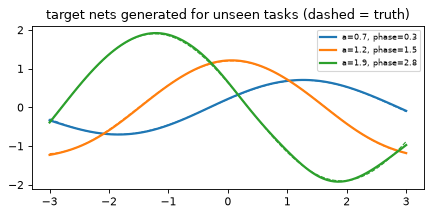

In [25]:
torch.manual_seed(0)
H_T = 16
n_target = H_T + H_T + H_T + 1                                 # w1 (1x16), b1 (16), w2 (16x1), b2 (1) = 49 weights
hyper = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, n_target))

def target_net(x, theta):
    # x: (tasks, points, 1); theta: (tasks, 49) -- every task gets its own generated weights
    w1 = theta[:, :H_T].unsqueeze(1); b1 = theta[:, H_T:2 * H_T].unsqueeze(1)
    w2 = theta[:, 2 * H_T:3 * H_T].unsqueeze(2); b2 = theta[:, 3 * H_T:].unsqueeze(1)
    return torch.tanh(x @ w1 + b1) @ w2 + b2

def sample_tasks(n_tasks, n_points):
    a = torch.rand(n_tasks, 1) * 1.5 + 0.5; phase = torch.rand(n_tasks, 1) * np.pi
    x = torch.rand(n_tasks, n_points, 1) * 6 - 3
    return torch.cat([a, phase], 1), x, a.unsqueeze(1) * torch.sin(x + phase.unsqueeze(1))

opt_h = torch.optim.Adam(hyper.parameters(), lr=2e-3); t0 = time.time()
for step_i in range(2000):
    z, x, y = sample_tasks(32, 40)
    loss = F.mse_loss(target_net(x, hyper(z)), y)
    opt_h.zero_grad(); loss.backward(); opt_h.step()
z, x, y = sample_tasks(200, 100)                              # 200 new, unseen tasks
with torch.no_grad(): test_loss = F.mse_loss(target_net(x, hyper(z)), y).item()
print(f"hypernetwork: {sum(p.numel() for p in hyper.parameters())} parameters, generates {n_target}-weight target nets")
print(f"MSE on 200 unseen tasks: {test_loss:.4f} (trained in {time.time() - t0:.1f}s)")

xg = torch.linspace(-3, 3, 100).reshape(1, 100, 1)
plt.figure(figsize=(5.5, 2.8))
for k, (a, ph) in enumerate([(0.7, 0.3), (1.2, 1.5), (1.9, 2.8)]):
    zt = torch.tensor([[a, ph]])
    with torch.no_grad(): yp = target_net(xg, hyper(zt)).squeeze()
    plt.plot(xg.squeeze(), a * np.sin(xg.squeeze() + ph), color=f"C{k}", ls="--", lw=1)
    plt.plot(xg.squeeze(), yp, color=f"C{k}", lw=2, label=f"a={a}, phase={ph}")
plt.title("target nets generated for unseen tasks (dashed = truth)"); plt.legend(fontsize=7); plt.tight_layout(); plt.show()

One hypernetwork produces a whole family of working networks, including for task settings it never saw during training.

**Modern relatives:**

| Idea | What is generated | Example use |
|---|---|---|
| **FiLM** / conditional normalisation (Perez et al., 2018) | per-channel scale and shift from a condition | conditioning image models on text or class labels; timestep conditioning in diffusion models |
| **Adapter / LoRA generators** | small low-rank weight updates ([LoRA and PEFT](12_advanced_peft.ipynb)) from a task description or a few examples | research such as HyperDreamBooth (2023) for fast personalisation, and "text-to-LoRA"-style generators |
| **Hypernetworks for continual learning** (von Oswald et al., 2020) | one weight set per task, from a task embedding | avoiding forgetting old tasks |
| **Weight generation in architecture search** (SMASH, 2017) | weights for candidate architectures | quick ranking of architectures |
| **Implicit neural representations** | weights of a small network that *is* a signal (image, 3D shape) | meta-learning compact representations |

**Used today:** mostly as conditioning layers (FiLM-style) inside larger models and in research on fast adaptation and personalisation. **Limits:** the output layer must produce many numbers (a full-size target network has millions of weights, so practical systems generate only small parts, low-rank factors or chunks); training can be unstable because small changes in $\phi$ change every target weight; quality on truly new tasks is limited by how well the task description covers them.

## 14. Mixture density networks (MDN)

**What it is:** a **mixture density network** (Christopher Bishop, 1994) is a normal network whose outputs are the **parameters of a probability distribution** over the target, specifically a **Gaussian mixture**: several bell curves, each with a weight, a centre and a width. So for each input it predicts *several possible answers and how likely each one is*.

**Simple analogy:** asked "where will this taxi go next from the airport?", a normal regression network answers with the average of all destinations (the middle of the sea). An MDN answers: "40% city centre, 35% business district, 25% the hotel zone", each with its own uncertainty.

**How it works:** for input $x$, the network outputs for each of $K$ components a mixing weight $\pi_k(x)$ (through a softmax so they sum to 1), a mean $\mu_k(x)$ and a standard deviation $\sigma_k(x)$ (through an exp so it is positive):

$$p(y \mid x) = \sum_{k=1}^{K} \pi_k(x)\,\mathcal{N}\big(y \mid \mu_k(x),\, \sigma_k(x)^2\big)$$

Train by minimising the **negative log-likelihood** (computed stably with log-sum-exp):

$$\mathcal{L} = -\frac1n\sum_{n} \log \sum_k \pi_k(x_n)\,\mathcal N\big(y_n \mid \mu_k(x_n), \sigma_k(x_n)^2\big)$$

**Why MSE fails here:** minimising squared error makes the network predict the **conditional mean** $\mathbb{E}[y\mid x]$. When several answers are valid (an **inverse problem**, e.g. which joint angles put a robot hand at this point), the mean of the valid answers is often itself invalid.

**Demo:** Bishop's classic toy. Generate $x = y + 0.3\sin(2\pi y) + \text{noise}$, then try to predict $y$ from $x$. For some $x$ there are three valid values of $y$.

In [26]:
rng_md = np.random.default_rng(0)
n_md = 1000
y_md = rng_md.uniform(0, 1, n_md)
x_md = y_md + 0.3 * np.sin(2 * np.pi * y_md) + rng_md.uniform(-0.1, 0.1, n_md)    # forward map is easy...
Xm = torch.tensor(x_md, dtype=torch.float32)[:, None]; Ym = torch.tensor(y_md, dtype=torch.float32)[:, None]   # ...we learn the inverse

torch.manual_seed(0)
mse_net = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1))
opt_m = torch.optim.Adam(mse_net.parameters(), lr=5e-3)
for _ in range(1500):
    loss = F.mse_loss(mse_net(Xm), Ym); opt_m.zero_grad(); loss.backward(); opt_m.step()

class MDN(nn.Module):
    def __init__(self, K=5, H=32):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(1, H), nn.Tanh(), nn.Linear(H, H), nn.Tanh())
        self.pi, self.mu, self.log_sigma = nn.Linear(H, K), nn.Linear(H, K), nn.Linear(H, K)
    def forward(self, x):
        h = self.body(x)
        return F.log_softmax(self.pi(h), -1), self.mu(h), self.log_sigma(h).clamp(-7, 2)

def mdn_nll(log_pi, mu, log_sigma, y):
    log_normal = -0.5 * ((y - mu) / log_sigma.exp()) ** 2 - log_sigma - 0.5 * math.log(2 * math.pi)
    return -torch.logsumexp(log_pi + log_normal, dim=-1).mean()

mdn = MDN(); opt_m = torch.optim.Adam(mdn.parameters(), lr=5e-3); t0 = time.time()
for _ in range(2500):
    loss = mdn_nll(*mdn(Xm), Ym); opt_m.zero_grad(); loss.backward(); opt_m.step()
print(f"MDN negative log-likelihood {loss.item():.3f} (trained in {time.time() - t0:.1f}s)")

with torch.no_grad():
    lp, mu, ls = mdn(torch.tensor([[0.5]]))
order = np.argsort(-lp.exp().numpy()[0])
print("mixture at x = 0.5 (weight, mean, std), largest first:")
for k in order[:3]:
    print(f"  pi={lp.exp()[0, k]:.2f}  mu={mu[0, k]:.2f}  sigma={ls.exp()[0, k]:.3f}")

MDN negative log-likelihood -1.054 (trained in 4.9s)
mixture at x = 0.5 (weight, mean, std), largest first:
  pi=0.54  mu=0.49  sigma=0.098
  pi=0.25  mu=0.78  sigma=0.039
  pi=0.21  mu=0.23  sigma=0.041


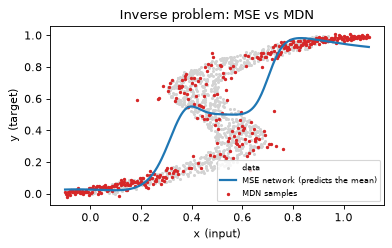

In [27]:
# sample from the MDN: pick a component by its weight, then sample from that Gaussian
xg = torch.linspace(-0.1, 1.1, 400)[:, None]
with torch.no_grad():
    lp, mu, ls = mdn(xg); y_mse = mse_net(xg)
comp = torch.multinomial(lp.exp(), 1)
samples_y = mu.gather(1, comp) + ls.exp().gather(1, comp) * torch.randn(len(xg), 1)
plt.figure(figsize=(5, 3.2))
plt.scatter(x_md, y_md, s=3, color="lightgray", label="data")
plt.plot(xg, y_mse, "C0", lw=2, label="MSE network (predicts the mean)")
plt.scatter(xg, samples_y, s=4, color="C3", label="MDN samples")
plt.xlabel("x (input)"); plt.ylabel("y (target)"); plt.legend(fontsize=7); plt.title("Inverse problem: MSE vs MDN")
plt.tight_layout(); plt.show()

The MSE network draws a line through the empty middle where no real data exists; the MDN samples follow all three branches.

**Used today:** handwriting generation (Graves, 2013, predicted pen movements with an MDN on top of an LSTM), Sketch-RNN, the "World Models" agent (Ha and Schmidhuber, 2018, an MDN-RNN), **multimodal trajectory prediction** for self-driving cars and pedestrians, inverse kinematics in robotics, and probabilistic forecasting heads ([probabilistic forecasting](../04_Forecasting/09_probabilistic_forecasting.ipynb)). For high-dimensional outputs such as robot action sequences or images, diffusion-based and autoregressive models have taken over much of this role.

**Limits:** training can be unstable (a component's $\sigma$ collapses onto a single point and the likelihood shoots up, hence the clamp in our code); you must choose $K$; components can go unused; it scales poorly to many output dimensions (full covariance matrices grow quadratically).

## 15. Bayesian neural networks (BNN), MC dropout and deep ensembles

**What it is:** in a normal network every weight is one number. In a **Bayesian neural network** every weight is a **probability distribution**. Instead of one prediction, you get a distribution of predictions, and its spread tells you how unsure the model is. This is especially useful away from the training data, where a normal network can be confidently wrong.

**Simple analogy:** asking one expert vs asking a committee of plausible experts. Where the committee agrees, you can trust the answer; where they disagree, you should be careful.

**Two kinds of uncertainty:**
- **Aleatoric**: noise in the data itself (a fair coin). More data does not remove it.
- **Epistemic**: the model's ignorance, because it saw little or no data there. More data reduces it. BNNs mainly target this one.

**How it works:**

- **Bayes' rule over weights:** $p(w \mid D) \propto p(D \mid w)\,p(w)$, and the **predictive distribution** averages over all plausible weights:
$$p(y \mid x, D) = \int p(y \mid x, w)\, p(w \mid D)\, dw \ \approx\ \frac1S \sum_{s=1}^{S} p(y \mid x, w_s), \quad w_s \sim p(w\mid D)$$
- The exact posterior is intractable, so we approximate. **Bayes by Backprop** (Blundell et al., 2015) uses **variational inference**: each weight gets a Gaussian $q(w) = \mathcal N(\mu, \sigma^2)$ with $\sigma = \log(1 + e^{\rho})$, sampled with the **reparameterisation trick** $w = \mu + \sigma\,\varepsilon$, $\varepsilon \sim \mathcal N(0,1)$, and trained by minimising
$$\mathcal{L} = \underbrace{\mathrm{KL}\big(q(w)\,\Vert\, p(w)\big)}_{\text{stay close to the prior}} \; - \; \underbrace{\mathbb{E}_{q(w)}\big[\log p(D \mid w)\big]}_{\text{fit the data}}$$
(the negative **ELBO**, evidence lower bound).
- **Practical approximations:**
  - **MC dropout** (Gal and Ghahramani, 2016): keep dropout switched on at prediction time and run the network many times; the spread of the outputs approximates Bayesian uncertainty.
  - **Deep ensembles** (Lakshminarayanan, Pritzel and Blundell, 2017): train 5-10 networks from different random starts and look at their disagreement. Simple and often the strongest baseline in practice.
  - Others: the **Laplace approximation** (a Gaussian around the trained weights), SWAG, and last-layer-only Bayesian methods.

**Demo:** 1D regression with two clusters of data and a gap between them. We compare Bayes by Backprop, MC dropout and a 5-member deep ensemble.

In [28]:
rng_b = np.random.default_rng(0)
x_b = np.r_[rng_b.uniform(-5, -2, 40), rng_b.uniform(2, 5, 40)]          # data with a gap in the middle
y_b = np.sin(x_b) + 0.1 * rng_b.standard_normal(80)
Xb_t = torch.tensor(x_b, dtype=torch.float32)[:, None]; Yb_t = torch.tensor(y_b, dtype=torch.float32)[:, None]
x_plot = torch.linspace(-8, 8, 300)[:, None]

class BayesLinear(nn.Module):
    # every weight has a mean (mu) and a softness parameter (rho): sigma = softplus(rho)
    def __init__(self, n_in, n_out, prior_sigma=1.0):
        super().__init__()
        self.w_mu = nn.Parameter(torch.randn(n_out, n_in) * 0.5); self.w_rho = nn.Parameter(torch.full((n_out, n_in), -4.0))
        self.b_mu = nn.Parameter(torch.zeros(n_out));             self.b_rho = nn.Parameter(torch.full((n_out,), -4.0))
        self.prior_sigma = prior_sigma
    def forward(self, x):
        w = self.w_mu + F.softplus(self.w_rho) * torch.randn_like(self.w_mu)   # reparameterisation trick
        b = self.b_mu + F.softplus(self.b_rho) * torch.randn_like(self.b_mu)
        return F.linear(x, w, b)
    def kl(self):
        # closed-form KL( N(mu, sigma^2) || N(0, prior^2) ), summed over all weights
        def kl_term(mu, sig): return (torch.log(self.prior_sigma / sig) + (sig ** 2 + mu ** 2) / (2 * self.prior_sigma ** 2) - 0.5).sum()
        return kl_term(self.w_mu, F.softplus(self.w_rho)) + kl_term(self.b_mu, F.softplus(self.b_rho))

class BNN(nn.Module):
    def __init__(self):
        super().__init__(); self.l1, self.l2, self.l3 = BayesLinear(1, 32), BayesLinear(32, 32), BayesLinear(32, 1)
    def forward(self, x): return self.l3(F.relu(self.l2(F.relu(self.l1(x)))))
    def kl(self): return self.l1.kl() + self.l2.kl() + self.l3.kl()

results = {}
torch.manual_seed(0); t0 = time.time()
bnn = BNN(); opt_b = torch.optim.Adam(bnn.parameters(), lr=1e-2)
NOISE_SD = 0.1                                                     # assumed data noise for the likelihood
for _ in range(2000):
    nll = ((bnn(Xb_t) - Yb_t) ** 2).sum() / (2 * NOISE_SD ** 2)    # -log p(D | w) up to a constant
    loss = nll + bnn.kl()                                          # negative ELBO
    opt_b.zero_grad(); loss.backward(); opt_b.step()
with torch.no_grad(): results["Bayes by Backprop"] = torch.stack([bnn(x_plot) for _ in range(100)]).squeeze(-1).numpy()
print(f"Bayes by Backprop trained in {time.time() - t0:.1f}s")

torch.manual_seed(0); t0 = time.time()
mc_net = nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))
opt_b = torch.optim.Adam(mc_net.parameters(), lr=1e-2, weight_decay=1e-4)
for _ in range(1500):
    loss = F.mse_loss(mc_net(Xb_t), Yb_t); opt_b.zero_grad(); loss.backward(); opt_b.step()
mc_net.train()                                                     # keep dropout ON at prediction time
with torch.no_grad(): results["MC dropout"] = torch.stack([mc_net(x_plot) for _ in range(100)]).squeeze(-1).numpy()
print(f"MC dropout trained in {time.time() - t0:.1f}s")

t0 = time.time(); members = []
for m in range(5):
    torch.manual_seed(m)                                           # only the random start differs
    net = nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    opt_b = torch.optim.Adam(net.parameters(), lr=1e-2)
    for _ in range(800):
        loss = F.mse_loss(net(Xb_t), Yb_t); opt_b.zero_grad(); loss.backward(); opt_b.step()
    with torch.no_grad(): members.append(net(x_plot).squeeze(-1).numpy())
results["Deep ensemble (5)"] = np.array(members)
print(f"deep ensemble trained in {time.time() - t0:.1f}s")

Bayes by Backprop trained in 4.4s


MC dropout trained in 1.4s


deep ensemble trained in 2.8s


method                  inside data (2<|x|<5)              gap (|x|<1)      far outside (|x|>6)   (average predictive std)
Bayes by Backprop                       0.146                    0.094                    0.335
MC dropout                              0.115                    0.180                    0.289
Deep ensemble (5)                       0.031                    0.574                    0.115


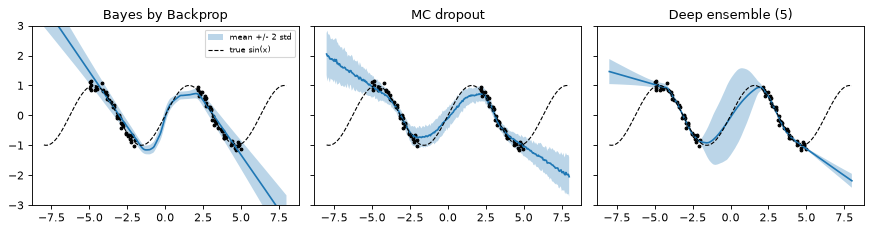

In [29]:
xp = x_plot.squeeze().numpy()
regions = {"inside data (2<|x|<5)": (np.abs(xp) > 2) & (np.abs(xp) < 5), "gap (|x|<1)": np.abs(xp) < 1, "far outside (|x|>6)": np.abs(xp) > 6}
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
print(f"{'method':20s}" + "".join(f"{r:>25s}" for r in regions) + "   (average predictive std)")
for ax, (name, S) in zip(axes, results.items()):
    mean, sd = S.mean(0), S.std(0)
    ax.fill_between(xp, mean - 2 * sd, mean + 2 * sd, alpha=0.3, label="mean +/- 2 std")
    ax.plot(xp, mean, "C0"); ax.plot(xp, np.sin(xp), "k--", lw=1, label="true sin(x)")
    ax.scatter(x_b, y_b, s=6, color="k"); ax.set_title(name); ax.set_ylim(-3, 3)
    print(f"{name:20s}" + "".join(f"{sd[mask].mean():25.3f}" for mask in regions.values()))
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

All three methods are much more uncertain somewhere outside the data than inside it, which is what we want. But they **disagree about where**: read the table. This is a known weakness: simple mean-field variational BNNs and MC dropout often under-estimate uncertainty *between* clusters of data ("in-between uncertainty", Foong et al., 2019), while ensembles of ReLU networks can be over-confident far away if all members happen to extrapolate the same way. No approximation is perfect; check uncertainty estimates on held-out or shifted data before relying on them.

**Used today:** deep ensembles and MC dropout are widely used where uncertainty matters: medical imaging triage, active learning (label the points the model is least sure about), Bayesian optimisation, safety checks in autonomous systems, and reinforcement learning exploration. Full BNNs are used in research and smaller scientific models (libraries such as Pyro, NumPyro, TensorFlow Probability). For guaranteed coverage without Bayesian assumptions, see [conformal prediction](../03_Machine_Learning/14_conformal_prediction/01_conformal_prediction.ipynb); for variational inference in general, see [EM, variational inference and sampling](../03_Machine_Learning/17_probabilistic_graphical_models/02_em_variational_inference_and_sampling.ipynb).

**Limits:** BNNs double the parameters (a mean and a spread per weight) and need many forward passes per prediction; variational approximations can be poorly calibrated; the choice of prior matters but is hard to set for millions of weights; ensembles cost $M$ times the training and serving compute.

## 16. Siamese / triplet networks and deep metric learning

**What it is:** a **Siamese network** runs two inputs through the **same** network (shared weights) and compares the resulting vectors (**embeddings**). It learns a **distance** in which "same" things are close and "different" things are far apart. This is **deep metric learning**. Early use: signature verification (Bromley, LeCun et al., 1993). The **contrastive loss** (Chopra, Hadsell and LeCun, 2005) works on pairs; the **triplet loss** (FaceNet, Schroff, Kalenichenko and Philbin, 2015) works on triplets of an **anchor**, a **positive** (same class) and a **negative** (different class):

$$\mathcal L = \max\big(0,\ \lVert f(a) - f(p)\rVert^2 - \lVert f(a) - f(n)\rVert^2 + m\big)$$

In words: the anchor must be closer to the positive than to the negative by at least a margin $m$.

**Simple analogy:** learning to recognise faces of people you have never met. You do not learn a class per person; you learn what makes two photos "the same person", which then works for anyone.

**Demo:** digits that are randomly **shifted by one pixel** (raw pixel distances are bad at this). We train a small CNN embedding with triplet loss on digits **0-6 only**, then test whether pairs of images are the same digit, including on digits **7-9 that were never used in training**. We report ROC-AUC (1.0 = perfect ranking of same-digit pairs above different-digit pairs, 0.5 = random).

In [30]:
rng_sm = np.random.default_rng(0); torch.manual_seed(0)
imgs = digits.images / 16.0; y_dig = digits.target
padded = np.pad(imgs, ((0, 0), (1, 1), (1, 1)))
shifted_all = np.stack([padded[:, 1 + dy:9 + dy, 1 + dx:9 + dx] for dy in (-1, 0, 1) for dx in (-1, 0, 1)], 1)   # 9 shifted copies
def random_shift(idx, r): return shifted_all[idx, r.integers(9, size=len(idx))]

perm = rng_sm.permutation(len(y_dig)); tr_idx, te_idx = perm[:1200], perm[1200:]
tr_seen = tr_idx[y_dig[tr_idx] < 7]                                       # train only on digits 0-6
by_cls = {c: tr_seen[y_dig[tr_seen] == c] for c in range(7)}

embed_net = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
                          nn.AdaptiveAvgPool2d(2), nn.Flatten(), nn.Linear(128, 32))
embed = lambda a: F.normalize(embed_net(torch.tensor(a, dtype=torch.float32)[:, None]), dim=1)   # unit-length embeddings
opt_t = torch.optim.Adam(embed_net.parameters(), lr=2e-3); triplet_loss = nn.TripletMarginLoss(margin=0.3)
t0 = time.time()
for step_i in range(400):
    a = rng_sm.choice(tr_seen, 64); ca = y_dig[a]
    p = np.array([rng_sm.choice(by_cls[c]) for c in ca])                 # positive: same digit
    cn = (ca + rng_sm.integers(1, 7, 64)) % 7
    n = np.array([rng_sm.choice(by_cls[c]) for c in cn])                  # negative: a different digit
    loss = triplet_loss(embed(random_shift(a, rng_sm)), embed(random_shift(p, rng_sm)), embed(random_shift(n, rng_sm)))
    opt_t.zero_grad(); loss.backward(); opt_t.step()
print(f"trained in {time.time() - t0:.1f}s, final triplet loss {loss.item():.3f}")

def pair_auc(idx, feats, r, n_pairs=4000):
    pairs = r.integers(len(idx), size=(n_pairs, 2))
    same = y_dig[idx][pairs[:, 0]] == y_dig[idx][pairs[:, 1]]
    dist = ((feats[pairs[:, 0]] - feats[pairs[:, 1]]) ** 2).sum(1)
    return roc_auc_score(same, -dist)

for label, idx in [("seen digits 0-6 (test images)", te_idx[y_dig[te_idx] < 7]), ("UNSEEN digits 7-9", te_idx[y_dig[te_idx] >= 7])]:
    shifted = random_shift(idx, np.random.default_rng(5))
    raw = shifted.reshape(len(idx), -1); raw = raw / np.linalg.norm(raw, axis=1, keepdims=True)
    with torch.no_grad(): emb = embed(shifted).numpy()
    print(f"{label:30s}: same-digit AUC raw pixels {pair_auc(idx, raw, np.random.default_rng(1)):.3f} | triplet embedding {pair_auc(idx, emb, np.random.default_rng(1)):.3f}")

trained in 5.9s, final triplet loss 0.008
seen digits 0-6 (test images) : same-digit AUC raw pixels 0.557 | triplet embedding 0.979
UNSEEN digits 7-9             : same-digit AUC raw pixels 0.544 | triplet embedding 0.676


On the digits used for training, the learned distance is far better than raw pixels, because it learned to ignore small shifts. On the **unseen** digits it is less good but still clearly better than raw pixels: the embedding has learned *general* features of "same handwritten shape", not just the seven training classes. This transfer is the whole point of metric learning (face verification works for people who were never in the training set).

**Used today:** very widely. Face verification and recognition, image and product search, person re-identification, signature and speaker verification, duplicate detection, **sentence embeddings** (Sentence-BERT is a Siamese network; see [sentence embeddings](../07_NLP/09_sentence_embeddings_advanced.ipynb)), **two-tower recommenders**, and CLIP-style contrastive image-text models ([self-supervised learning](09_self_supervised_learning.ipynb)). **Limits:** quality depends heavily on how triplets or pairs are chosen (easy triplets give zero loss and no learning, so "hard negative mining" is needed); large batches help; embeddings can encode unwanted bias; a threshold for "same" must be calibrated per application.

### Pointers: networks taught elsewhere in this repo

| Network | One line | Go to |
|---|---|---|
| MLP / DNN, backprop | stacked dense layers trained by the chain rule | [01](01_neural_network_fundamentals.ipynb), [18](18_neural_networks_from_scratch_numpy.ipynb) |
| CNN, ResNet | convolution filters, residual skip connections | [03 CNN](03_cnn.ipynb), [image classification](../06_Computer_Vision/02_image_classification.ipynb) |
| U-Net | encoder-decoder CNN with skip connections, for segmentation and diffusion | [image segmentation](../06_Computer_Vision/04_image_segmentation.ipynb) |
| TCN | causal, dilated 1D convolutions for sequences | [deep learning forecasting](../04_Forecasting/04_deep_learning_forecasting.ipynb) |
| RNN, LSTM, GRU | recurrent hidden state with gates | [04](04_rnn_lstm_gru.ipynb), [19](19_sequence_models_hands_on.ipynb) |
| Transformer, ViT | self-attention over tokens or image patches | [05](05_transformers_architecture.ipynb), [vision transformers](../06_Computer_Vision/05_vision_transformers.ipynb) |
| Autoencoder, VAE, GAN, diffusion, normalizing flows | generative models | [06](06_generative_models.ipynb), [20](20_generative_models_hands_on.ipynb) |
| GNN (GCN, GraphSAGE, GAT) | message passing on graphs | [07](07_gnn.ipynb), [21](21_graph_machine_learning_hands_on.ipynb) |
| Neural ODE, KAN | continuous-depth networks; learnable activation functions on edges | [10 neural ODE](10_neural_ode.ipynb) |
| Mixture of experts | a router sends each token to a few expert sub-networks | [LLM architecture innovations](../08_LLM/14_llm_architecture_innovations.ipynb) |
| Tabular deep learning | TabNet, FT-Transformer and friends | [14 tabular DL](14_tabular_deep_learning.ipynb) |
| PINNs, neural operators, Hamiltonian nets, INRs, equivariant nets, state-space models | scientific ML and modern architectures | [Part 2 of this zoo](24_neural_network_zoo_scientific_and_modern_architectures.ipynb) |

## 17. Summary table

| Network | Idea in one line | Still used today? (as of late 2026) | Typical uses | Main limits |
|---|---|---|---|---|
| Perceptron | one neuron, step output, error-driven updates | teaching only; the neuron inside every net | history, linear classification | only straight-line boundaries (no XOR) |
| MLP / DNN | stacked layers + non-linearities, trained with backprop | yes, everywhere | tabular data, heads, transformer FFN blocks | no built-in structure for images, sequences, graphs |
| RBF network | weighted sum of Gaussian bumps around centres | niche; RBF kernels are common | low-dim regression, interpolation, control | curse of dimensionality, width tuning |
| Extreme learning machine | random fixed hidden layer + least-squares readout | niche | very fast training on small problems | needs many units, no learned features |
| Self-organising map | grid of units that preserves neighbourhoods | niche | exploratory visualisation, clustering, monitoring | no clear objective; t-SNE/UMAP often better |
| Hopfield network | Hebbian weights, energy descent to stored memories | classic: teaching; modern: as attention | associative memory, theory of attention | classic capacity about 0.14 N, spurious states |
| Boltzmann machine / RBM / DBN | stochastic energy model with hidden units, trained by CD | mostly historical | pretraining (2006-2012), physics (neural quantum states) | intractable Z, slow sampling |
| Energy-based model | network outputs a scalar energy; sample with Langevin | research; idea lives in diffusion and OOD scores | generation, OOD detection, compositional models | slow sampling, unstable training |
| Echo state network / LSM | fixed random reservoir + trained linear readout | active niche | chaotic time series, physical / edge computing | limited memory, hyperparameter sensitive |
| LTC / CfC (liquid NNs) | ODE neurons with input-dependent time constants | niche, growing in control | robot / drone control, irregular time series | slow ODE training (LTC), small ecosystem |
| Spiking neural network | neurons communicate with timed spikes | research and low-power edge | neuromorphic chips, event cameras | hard training, needs special hardware for gains |
| Capsule network | vector neurons + routing by agreement | rarely | small-data vision research | slow routing, did not scale |
| Memory networks / NTM / DNC | controller + soft read/write external memory | ideas live on (attention, RAG) | algorithmic tasks, QA (historical) | unstable, slow; replaced by attention + retrieval |
| Hypernetwork | a network that outputs another network's weights | yes, mainly as conditioning (FiLM, adapter generators) | fast adaptation, personalisation, continual learning | huge outputs, instability |
| Mixture density network | outputs a Gaussian mixture over targets | yes, in specific heads | multimodal prediction, trajectories, inverse problems | component collapse, choosing K |
| Bayesian NN / MC dropout / ensembles | distribution over weights -> uncertainty | ensembles and MC dropout: yes; full BNNs: research | active learning, safety-critical triage, Bayesian optimisation | cost, calibration not guaranteed |
| Siamese / triplet network | shared encoder trained to make a distance | yes, widely | face verification, search, sentence embeddings, recommenders | needs good pair / triplet mining |

## Interview questions

**1. Why can a single perceptron not learn XOR, and what fixed it?**
XOR's two classes cannot be separated by one straight line, and a perceptron can only draw one line. Adding a hidden layer (an MLP) with smooth activations, trained with backpropagation, lets the network bend the space so the classes become separable.

**2. What is the difference between an RBF network and an extreme learning machine?**
Both train only a linear output layer with least squares. An RBF network's hidden units are local Gaussian bumps with chosen centres (often from k-means); an ELM's hidden units are random projections followed by a non-linearity.

**3. What is the capacity of a classic Hopfield network, and how do modern Hopfield networks relate to attention?**
About $0.14N$ random patterns for $N$ neurons. Modern Hopfield networks use an exponential energy whose update is $X^\top \operatorname{softmax}(\beta X\xi)$, which is the attention formula with stored patterns as keys and values; capacity becomes exponential.

**4. Why is contrastive divergence needed to train an RBM?**
The exact log-likelihood gradient needs expectations under the model distribution, which requires the intractable partition function or very long sampling. CD approximates the model term with samples obtained after a few Gibbs steps starting from the data.

**5. In an echo state network, what is trained and what does the spectral radius control?**
Only the linear readout is trained (ridge regression). The spectral radius of the random recurrent matrix controls how long inputs echo in the reservoir: too small means short memory, too large means chaotic, input-independent dynamics.

**6. What does "liquid" mean in liquid time-constant networks?**
Each neuron's effective time constant $\tau/(1 + \tau f(x, I))$ depends on the current input and state, so the speed at which neurons react changes ("flows") with the input. CfC networks approximate the ODE solution in closed form to avoid a numerical solver.

**7. How do you train a spiking neural network with backpropagation if spikes are not differentiable?**
Use surrogate gradients: keep the hard threshold in the forward pass but substitute a smooth derivative (e.g. a fast sigmoid) in the backward pass, and unroll the network over time like an RNN. Alternatives: convert a trained ANN to an SNN, or use local rules like STDP.

**8. When would you choose a mixture density network over a normal regression network?**
When one input can have several valid outputs (multimodal targets, inverse problems, trajectory prediction). MSE regression predicts the conditional mean, which may fall between the valid answers.

**9. Name three practical ways to get uncertainty estimates from a neural network.**
Deep ensembles (train several networks, measure disagreement), MC dropout (keep dropout on at test time, sample many passes), and variational BNNs such as Bayes by Backprop; also the Laplace approximation and conformal prediction for coverage guarantees.

**10. Why does a triplet network generalise to classes it never saw, while a classifier does not?**
A classifier learns one output per known class. A triplet network learns a distance function ("same vs different"), which can be applied to any new pair of inputs; new classes only need a few reference examples.

## Further reading

- Fjodor van Veen and Stefan Leijnen, *The Neural Network Zoo* (Asimov Institute, 2016 and 2019 update): the illustrated catalogue that inspired this notebook's title.
- F. Rosenblatt (1958), "The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain", *Psychological Review*. M. Minsky and S. Papert (1969), *Perceptrons*. D. Rumelhart, G. Hinton and R. Williams (1986), "Learning representations by back-propagating errors", *Nature*.
- D. Broomhead and D. Lowe (1988), "Multivariable functional interpolation and adaptive networks" (RBF networks). G.-B. Huang, Q.-Y. Zhu and C.-K. Siew (2006), "Extreme learning machine: theory and applications", *Neurocomputing*.
- T. Kohonen (1982), "Self-organized formation of topologically correct feature maps", *Biological Cybernetics*.
- J. J. Hopfield (1982), "Neural networks and physical systems with emergent collective computational abilities", *PNAS*. H. Ramsauer et al. (2020), "Hopfield Networks is All You Need" (arXiv:2008.02217). D. Krotov and J. Hopfield (2016), "Dense Associative Memory for Pattern Recognition".
- G. Hinton (2002), "Training Products of Experts by Minimizing Contrastive Divergence", *Neural Computation*; G. Hinton (2010), "A Practical Guide to Training Restricted Boltzmann Machines"; G. Hinton, S. Osindero and Y.-W. Teh (2006), "A fast learning algorithm for deep belief nets", *Neural Computation*.
- Y. LeCun et al. (2006), "A Tutorial on Energy-Based Learning". Y. Du and I. Mordatch (2019), "Implicit Generation and Modeling with Energy-Based Models".
- H. Jaeger (2001), "The 'echo state' approach to analysing and training recurrent neural networks", GMD Report 148. W. Maass, T. Natschlager and H. Markram (2002), "Real-time computing without stable states" (liquid state machines). M. Lukosevicius (2012), "A Practical Guide to Applying Echo State Networks".
- R. Hasani, M. Lechner, A. Amini, D. Rus and R. Grosu (2021), "Liquid Time-constant Networks", AAAI (arXiv:2006.04439). R. Hasani et al. (2022), "Closed-form continuous-time neural networks", *Nature Machine Intelligence*.
- W. Maass (1997), "Networks of spiking neurons: the third generation of neural network models". E. Neftci, H. Mostafa and F. Zenke (2019), "Surrogate Gradient Learning in Spiking Neural Networks", *IEEE Signal Processing Magazine*. S. Song, K. Miller and L. Abbott (2000), "Competitive Hebbian learning through spike-timing-dependent synaptic plasticity", *Nature Neuroscience*.
- S. Sabour, N. Frosst and G. Hinton (2017), "Dynamic Routing Between Capsules", NeurIPS (arXiv:1710.09829).
- J. Weston, S. Chopra and A. Bordes (2014), "Memory Networks". A. Graves, G. Wayne and I. Danihelka (2014), "Neural Turing Machines" (arXiv:1410.5401). A. Graves et al. (2016), "Hybrid computing using a neural network with dynamic external memory", *Nature*.
- D. Ha, A. Dai and Q. Le (2016), "HyperNetworks" (arXiv:1609.09106). E. Perez et al. (2018), "FiLM: Visual Reasoning with a General Conditioning Layer".
- C. M. Bishop (1994), "Mixture Density Networks", Aston University technical report NCRG/94/004.
- C. Blundell, J. Cornebise, K. Kavukcuoglu and D. Wierstra (2015), "Weight Uncertainty in Neural Networks" (Bayes by Backprop, arXiv:1505.05424). Y. Gal and Z. Ghahramani (2016), "Dropout as a Bayesian Approximation". B. Lakshminarayanan, A. Pritzel and C. Blundell (2017), "Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles".
- J. Bromley et al. (1993), "Signature Verification using a Siamese Time Delay Neural Network". F. Schroff, D. Kalenichenko and J. Philbin (2015), "FaceNet: A Unified Embedding for Face Recognition and Clustering".

## Next

[Part 2 of the zoo](24_neural_network_zoo_scientific_and_modern_architectures.ipynb) covers scientific machine learning and modern architectures (PINNs, neural operators, Hamiltonian networks, KAN, implicit neural representations, equivariant networks, modern sequence and vision designs, mixture of experts). For the mainstream families, continue with [05 transformers](05_transformers_architecture.ipynb), [06 generative models](06_generative_models.ipynb) and [10 neural ODE](10_neural_ode.ipynb).

In [31]:
print(f"Total notebook run time: {time.time() - NB_START:.0f} seconds")

Total notebook run time: 90 seconds
